# Inteligência de dados aplicada ao consumo de energia elétrica
## Da medição aos perfis de carga e à gestão da demanda

Este estudo desenvolve um fluxo completo de ciência de dados para Engenharia Elétrica: obtenção de medições públicas, diagnóstico da qualidade, tratamento de dados, construção de indicadores, análise estatística, aprendizado não supervisionado e interpretação aplicada. A pergunta central é: **quais regimes diários de consumo se repetem e que evidências fornecem para a gestão da demanda?**

O sistema estudado é uma residência instrumentada. Na primeira parte, cada observação corresponde a um minuto. Após a agregação, cada observação corresponde a um dia da mesma residência. Portanto, os agrupamentos representam **tipos de dia**, e não classes de consumidores. Essa distinção determina a interpretação dos resultados e a maneira de transportar o procedimento para medidores de uma rede inteligente.

O arquivo contém teoria antes de cada algoritmo, explicação de sua implementação e interpretação dos resultados. As interpretações numéricas são produzidas com os valores calculados na execução. A segmentação principal considera intensidade e distribuição do consumo; uma análise complementar utiliza o formato das curvas horárias.

### Execução no Google Colab

No [Google Colab](https://colab.research.google.com/), utilize **Arquivo > Fazer upload de notebook** e selecione este arquivo. Execute as células na ordem ou utilize **Ambiente de execução > Executar tudo**. O processamento utiliza CPU e não exige GPU. O download inicial é de aproximadamente 20 MB; a leitura utiliza o arquivo descompactado de aproximadamente 133 MB. O tempo depende da conexão e do ambiente. Os dados são públicos e não exigem cadastro nem chave de API.

Para repetir as análises com os mesmos critérios, mantenha os parâmetros iniciais. Se algum parâmetro for alterado, execute novamente todas as células seguintes. Os gráficos e tabelas já presentes registram a execução de verificação; a nova execução os substitui.

### Origem e significado das medições

A base **Individual Household Electric Power Consumption**, de Georges Hebrail e Alice Berard, foi publicada no UCI Machine Learning Repository. Reúne 2.075.259 registros de uma residência em Sceaux, França, entre dezembro de 2006 e novembro de 2010. Sua licença é CC BY 4.0. [Base e documentação original](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption), [DOI](https://doi.org/10.24432/C58K54).

| Campo original | Significado | Unidade ou representação |
|---|---|---|
| `Date`, `Time` | Data e horário da medição | `dd/mm/aaaa`, `hh:mm:ss` |
| `Global_active_power` | Potência ativa média no minuto | kW |
| `Global_reactive_power` | Potência reativa média no minuto | Unidade descrita como kW no catálogo; exige confirmação metrológica |
| `Voltage` | Tensão média no minuto | V |
| `Global_intensity` | Corrente média no minuto | A |
| `Sub_metering_1` | Energia no circuito da cozinha | Wh por intervalo de um minuto |
| `Sub_metering_2` | Energia no circuito da lavanderia | Wh por intervalo de um minuto |
| `Sub_metering_3` | Energia no circuito com aquecedor de água e ar-condicionado | Wh por intervalo de um minuto |

Potência reativa é usualmente expressa em var e seus múltiplos. Como a documentação apresenta uma inconsistência de unidade, o campo será preservado e auditado, mas não empregado no cálculo de fator de potência ou em conclusões quantitativas sobre compensação reativa. Os horários serão tratados conforme o calendário registrado, sem atribuir um fuso ausente no arquivo.

O encadeamento analítico é: **medição → qualidade → energia e indicadores → estatística → representação numérica → agrupamento → evidência operacional**. Cada transformação precisa preservar o significado físico das grandezas.

## 1. Preparação do ambiente e critérios da análise

Uma análise reprodutível explicita bibliotecas, sementes aleatórias e critérios de seleção. A semente controla etapas estocásticas, como a inicialização dos centroides, e permite repetir a execução no mesmo ambiente. Pequenas diferenças entre versões ainda podem ocorrer.

Serão interpoladas somente lacunas internas de até cinco minutos. Um dia será aceito se possuir os 1.440 valores de potência após esse procedimento e pelo menos 98% de medições originais válidas. Esses são critérios deste estudo, escolhidos para evitar que dias incompletos pareçam dias de baixo consumo. A janela das 18h às 22h será uma **janela de interesse analítico**, sem atribuição de tarifa ou horário de ponta regulamentado.

In [1]:
import sys, subprocess, importlib.util

dependencias = {
    'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
    'seaborn': 'seaborn', 'scipy': 'scipy', 'sklearn': 'scikit-learn',
    'IPython': 'ipython', 'joblib': 'joblib'
}
faltantes = [pacote for modulo, pacote in dependencias.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *faltantes])

import json, hashlib, shutil, urllib.request, zipfile, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn, joblib
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, adjusted_rand_score)
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

SEMENTE = 42
MAX_LACUNA_MIN = 5
COBERTURA_ORIGINAL_MIN = 0.98
HORAS_NOITE = list(range(18, 22))
PASTA_DADOS = Path('dados')
PASTA_DADOS.mkdir(exist_ok=True)
threadpool_limits(limits=2)
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 115,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 14)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.precision', 3)

def br(valor, casas=2):
    return f'{valor:,.{casas}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def analise(texto):
    display(Markdown('**Análise dos resultados.** ' + texto))

versoes = {'Python': platform.python_version(), 'pandas': pd.__version__,
           'NumPy': np.__version__, 'scikit-learn': sklearn.__version__,
           'SciPy': scipy.__version__}
display(pd.Series(versoes, name='Versão').to_frame())
analise('O ambiente está preparado. As versões acima e os parâmetros definidos '
        'registram as condições de reprodução; ainda não há uma conclusão sobre o consumo.')

,Versão
Python,3.12.13
pandas,2.2.3
NumPy,2.3.5
scikit-learn,1.8.0
SciPy,1.17.0


**Análise dos resultados.** O ambiente está preparado. As versões acima e os parâmetros definidos registram as condições de reprodução; ainda não há uma conclusão sobre o consumo.

**Explicação do algoritmo**

O primeiro bloco verifica se as dependências existem e instala apenas as ausentes. As importações disponibilizam ferramentas de tabelas, visualização, estatística e agrupamento. `Path` organiza caminhos de forma compatível com o Colab e com uma instalação local.

Os parâmetros concentram as decisões que afetam o resultado. `threadpool_limits` limita o paralelismo numérico para evitar sobrecarga em máquinas pequenas. `br` formata os números em português e `analise` apresenta comentários calculados junto às saídas. Essas funções apenas organizam a apresentação; não modificam os dados.

## 2. Obtenção dos dados e rastreabilidade

O fluxo começa no arquivo original. O download deve produzir uma cópia identificável, preservada antes do tratamento. Um resumo criptográfico SHA-256 funciona como uma impressão digital do arquivo: permite verificar se duas execuções utilizaram exatamente os mesmos bytes. Ele não certifica a qualidade das medições, mas registra a versão efetivamente utilizada.

O arquivo ZIP será lido diretamente, sem extrair conteúdo arbitrário. Se o endereço estiver indisponível, a execução apresentará um erro explícito. Também é possível colocar o ZIP original em `dados/household_power_consumption.zip` pelo painel de arquivos do Colab e executar novamente a célula.

In [2]:
URL_DADOS = ('https://archive.ics.uci.edu/static/public/235/'
             'individual+household+electric+power+consumption.zip')
ARQUIVO_ZIP = PASTA_DADOS / 'household_power_consumption.zip'
NOME_INTERNO = 'household_power_consumption.txt'

if not ARQUIVO_ZIP.exists() or not zipfile.is_zipfile(ARQUIVO_ZIP):
    temporario = ARQUIVO_ZIP.with_suffix('.download')
    try:
        with urllib.request.urlopen(URL_DADOS, timeout=90) as resposta:
            with temporario.open('wb') as destino:
                shutil.copyfileobj(resposta, destino)
        if not zipfile.is_zipfile(temporario):
            raise ValueError('O conteúdo recebido não é um ZIP válido.')
        temporario.replace(ARQUIVO_ZIP)
    except Exception as erro:
        temporario.unlink(missing_ok=True)
        raise RuntimeError('Falha no download. Envie o ZIP original para '
                           'dados/household_power_consumption.zip e repita a célula.') from erro

with zipfile.ZipFile(ARQUIVO_ZIP) as arquivo:
    assert NOME_INTERNO in arquivo.namelist(), 'Arquivo de medições não encontrado.'
    assert arquivo.testzip() is None, 'ZIP corrompido.'
    tamanho_txt = arquivo.getinfo(NOME_INTERNO).file_size

sha256 = hashlib.sha256(ARQUIVO_ZIP.read_bytes()).hexdigest()
print('Fonte:', URL_DADOS)
print('SHA-256:', sha256)
print('ZIP:', br(ARQUIVO_ZIP.stat().st_size / 1e6), 'MB')
analise(f'O arquivo validado contém {br(tamanho_txt / 1e6)} MB de dados tabulares. '
        'A cópia original será mantida, permitindo separar evidência bruta e transformações.')

Fonte: https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip
SHA-256: 9f84b46ade8a2d8e1286ec4b2b6c2987a45a755c59f263be3b3b3d10dfbda3ff
ZIP: 20,64 MB


**Análise dos resultados.** O arquivo validado contém 132,96 MB de dados tabulares. A cópia original será mantida, permitindo separar evidência bruta e transformações.

**Explicação do algoritmo**

A condição inicial reaproveita um ZIP já existente e válido. Caso necessário, o download escreve primeiro em um arquivo temporário; a troca de nome ocorre somente após a validação do formato. Assim, uma interrupção não deixa um arquivo parcial com aparência de arquivo final.

`testzip` verifica a integridade interna do arquivo comprimido. A verificação de `NOME_INTERNO` confirma que o conteúdo esperado existe. O SHA-256 é calculado sobre o ZIP inteiro e será incluído nos metadados exportados ao final. Nenhuma linha é modificada nesta etapa.

## 3. Leitura e inspeção inicial

Data wrangling começa pela compreensão do formato. O separador desta base é ponto e vírgula, enquanto o separador decimal é ponto. O marcador `?` e campos vazios representam ausência de informação. Ler um marcador como texto ou substituir uma ausência por zero pode distorcer médias, energia e agrupamentos.

A primeira leitura preserva os campos como texto. Isso permite distinguir um valor originalmente ausente de um conteúdo que falhou na conversão numérica. A tabela exibida é apenas uma amostra para inspeção; o processamento utiliza todos os registros.

In [3]:
with zipfile.ZipFile(ARQUIVO_ZIP) as arquivo:
    with arquivo.open(NOME_INTERNO) as fluxo:
        bruto = pd.read_csv(fluxo, sep=';', dtype='string',
                            na_values=['?', '', 'NA', 'null'], keep_default_na=True)

n_linhas_brutas = len(bruto)
display(bruto.head(6))
display(pd.DataFrame({'tipo_inicial': bruto.dtypes.astype(str),
                      'ausentes': bruto.isna().sum(),
                      'ausentes_%': bruto.isna().mean() * 100}))
analise(f'Foram obtidos {br(n_linhas_brutas, 0)} registros e {br(bruto.shape[1], 0)} campos. '
        f'{br(bruto.isna().any(axis=1).sum(), 0)} linhas apresentam ao menos uma ausência. '
        'Essas linhas representam falhas de observação e não serão interpretadas como consumo nulo.')

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.000
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.000
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.000
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.000
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.000
5,16/12/2006,17:29:00,3.520,0.522,235.020,15.000,0.000,2.000,17.000


,tipo_inicial,ausentes,ausentes_%
Date,string,0,0.000
Time,string,0,0.000
Global_active_power,string,25979,1.252
Global_reactive_power,string,25979,1.252
Voltage,string,25979,1.252
Global_intensity,string,25979,1.252
Sub_metering_1,string,25979,1.252
Sub_metering_2,string,25979,1.252
Sub_metering_3,string,25979,1.252


**Análise dos resultados.** Foram obtidos 2.075.259 registros e 9 campos. 25.979 linhas apresentam ao menos uma ausência. Essas linhas representam falhas de observação e não serão interpretadas como consumo nulo.

**Explicação do algoritmo**

`ZipFile.open` fornece o arquivo interno diretamente ao `read_csv`. O argumento `sep` define a separação entre campos e `dtype='string'` adia a interpretação numérica. `na_values` reconhece os marcadores de ausência já na leitura.

`isna().sum()` conta ausências por coluna. A média de uma máscara booleana corresponde à proporção de ocorrências verdadeiras, por isso `isna().mean() * 100` calcula o percentual. `any(axis=1)` identifica linhas com pelo menos um campo ausente. Esse diagnóstico orientará a seleção de uma política de tratamento.

## 4. Conversão de tipos e construção do índice temporal

Uma coluna numérica precisa permitir operações matemáticas, e uma coluna temporal precisa permitir ordenação e agregação. A conversão será explícita: datas seguem o formato dia/mês/ano e horários incluem segundos. `errors='coerce'` transforma conteúdo inválido em ausência, cuja quantidade é registrada para evitar falhas silenciosas.

A integridade do índice temporal é essencial. Dois registros no mesmo instante podem representar uma duplicação ou um conflito de medição. Registros idênticos serão consolidados; valores diferentes no mesmo instante interromperão o fluxo para investigação. Uma média automática esconderia esse conflito.

In [4]:
mapa_nomes = {
    'Global_active_power': 'potencia_kw',
    'Global_reactive_power': 'reativa_original',
    'Voltage': 'tensao_v', 'Global_intensity': 'corrente_a',
    'Sub_metering_1': 'cozinha_wh', 'Sub_metering_2': 'lavanderia_wh',
    'Sub_metering_3': 'aquecimento_climatizacao_wh'
}
instantes = pd.to_datetime(bruto['Date'] + ' ' + bruto['Time'],
                          format='%d/%m/%Y %H:%M:%S', errors='coerce')
dados = pd.DataFrame(index=bruto.index)
falhas_conversao = {}
for origem, destino in mapa_nomes.items():
    convertido = pd.to_numeric(bruto[origem], errors='coerce')
    falhas_conversao[destino] = int((bruto[origem].notna() & convertido.isna()).sum())
    dados[destino] = convertido.astype('float32')
dados['instante'] = instantes
n_datas_invalidas = int(dados['instante'].isna().sum())
dados = dados.loc[dados['instante'].notna()].set_index('instante').sort_index()

duplicados = dados.loc[dados.index.duplicated(keep=False)]
if len(duplicados):
    conflitos = duplicados.groupby(level=0).nunique(dropna=False).gt(1).any(axis=1)
    if conflitos.any():
        raise ValueError('Há medições conflitantes no mesmo instante; inspecione duplicados.')
n_duplicatas = int(dados.index.duplicated().sum())
dados = dados.loc[~dados.index.duplicated(keep='first')]
indice_regular = pd.date_range(dados.index.min(), dados.index.max(), freq='min')
n_instantes_inseridos = len(indice_regular.difference(dados.index))
dados = dados.reindex(indice_regular)
dados.index.name = 'instante'
del bruto, instantes

display(pd.Series(falhas_conversao, name='Falhas de conversão numérica').to_frame())
print('Período:', dados.index.min(), 'até', dados.index.max())
analise(f'Foram identificadas {n_datas_invalidas} datas inválidas, {n_duplicatas} duplicatas '
        f'redundantes e {n_instantes_inseridos} instantes ausentes do calendário. '
        'O índice agora está ordenado em intervalos de um minuto; lacunas de medição continuam visíveis.')

,Falhas de conversão numérica
potencia_kw,0
reativa_original,0
tensao_v,0
corrente_a,0
cozinha_wh,0
lavanderia_wh,0
aquecimento_climatizacao_wh,0


Período: 2006-12-16 17:24:00 até 2010-11-26 21:02:00


**Análise dos resultados.** Foram identificadas 0 datas inválidas, 0 duplicatas redundantes e 0 instantes ausentes do calendário. O índice agora está ordenado em intervalos de um minuto; lacunas de medição continuam visíveis.

**Explicação do algoritmo**

O dicionário renomeia variáveis e registra unidades nos nomes. O laço converte cada campo e conta apenas as novas ausências produzidas pela conversão, separando-as daquelas já identificadas na leitura. `float32` reduz o uso de memória; agregações físicas utilizarão precisão de 64 bits.

O índice temporal é construído, ordenado e verificado. `duplicated(keep=False)` seleciona todas as ocorrências repetidas e `nunique(dropna=False)` verifica conflitos, incluindo diferenças entre presença e ausência. `reindex` explicita instantes faltantes sem inventar medições. Por fim, objetos de texto que não serão mais usados são liberados da memória.

## 5. Plausibilidade física e identificação de valores extremos

Uma observação estatisticamente extrema pode ser fisicamente válida. O acionamento simultâneo de cargas pode produzir um pico importante para a engenharia. Por isso, limites estatísticos servirão para sinalizar observações, sem excluí-las automaticamente.

Neste conjunto residencial de consumo, valores negativos nos canais de consumo e tensão não positiva serão tratados como inválidos. Essa regra depende do contexto: em um medidor bidirecional com geração distribuída, potência ativa negativa pode representar exportação legítima. Para sinalizar extremos, utiliza-se a regra de Tukey: $IQR=Q_3-Q_1$, limite inferior $Q_1-1{,}5IQR$ e limite superior $Q_3+1{,}5IQR$. Ela não pressupõe uma distribuição normal.

In [5]:
invalidos = pd.DataFrame(False, index=dados.index, columns=dados.columns)
for coluna in dados.columns:
    invalidos[coluna] = dados[coluna].lt(0)
invalidos['tensao_v'] = dados['tensao_v'].le(0)
contagem_invalidos = invalidos.sum()
dados = dados.mask(invalidos)
del invalidos

q1, q3 = dados['potencia_kw'].quantile([0.25, 0.75])
limite_tukey = q3 + 1.5 * (q3 - q1)
n_extremos = int(dados['potencia_kw'].gt(limite_tukey).sum())
display(contagem_invalidos.rename('Inválidos por regra física').to_frame())
print('Limite superior de Tukey:', br(limite_tukey), 'kW')
print('Maior potência registrada:', br(dados['potencia_kw'].max()), 'kW')
analise(f'{br(n_extremos, 0)} medições excedem {br(limite_tukey)} kW. '
        'Elas permanecem na análise porque a regra identifica raridade, sem demonstrar erro. '
        'Sua remoção reduziria artificialmente a demanda de pico observada.')

,Inválidos por regra física
potencia_kw,0
reativa_original,0
tensao_v,0
corrente_a,0
cozinha_wh,0
lavanderia_wh,0
aquecimento_climatizacao_wh,0


Limite superior de Tukey: 3,36 kW
Maior potência registrada: 11,12 kW


**Análise dos resultados.** 94.907 medições excedem 3,36 kW. Elas permanecem na análise porque a regra identifica raridade, sem demonstrar erro. Sua remoção reduziria artificialmente a demanda de pico observada.

**Explicação do algoritmo**

A máscara `invalidos` reúne as regras físicas e `mask` substitui somente as posições sinalizadas por valores ausentes. A contagem é obtida antes da substituição para documentar a intervenção. Não se utiliza um limite arbitrário de tensão adequado ao Brasil para filtrar uma residência francesa.

Os quartis são calculados sobre a potência observada. A comparação `gt` conta medições acima do limite de Tukey, mas não altera o conjunto. Essa separação entre sinalização e remoção preserva eventos de carga que poderão explicar os perfis diários.

## 6. Tratamento de ausências com interpolação temporal restrita

Interpolar significa estimar valores entre observações conhecidas. Na interpolação linear temporal, para $t_a<t<t_b$, utiliza-se $\hat{x}(t)=x(t_a)+[x(t_b)-x(t_a)](t-t_a)/(t_b-t_a)$. A hipótese é de variação aproximadamente linear durante uma lacuna curta. Um acionamento ocorrido inteiramente na lacuna não pode ser recuperado por esse método.

Lacunas longas serão preservadas. Preencher vários dias com a média poderia criar um perfil artificial de consumo constante. Além disso, aplicar apenas `limit=5` poderia preencher o início de uma lacuna maior; o algoritmo verificará o **comprimento total de cada sequência ausente** antes de aceitar uma estimativa.

Esta é uma análise retrospectiva. A interpolação utiliza observações posteriores ao instante estimado; para um sistema em tempo real, seria necessário adotar um procedimento causal.

,ausentes_antes,preenchidos,ausentes_depois
variavel,,,
potencia_kw,25979,76,25903
reativa_original,25979,76,25903
tensao_v,25979,76,25903
corrente_a,25979,76,25903
cozinha_wh,25979,76,25903
lavanderia_wh,25979,76,25903
aquecimento_climatizacao_wh,25979,76,25903


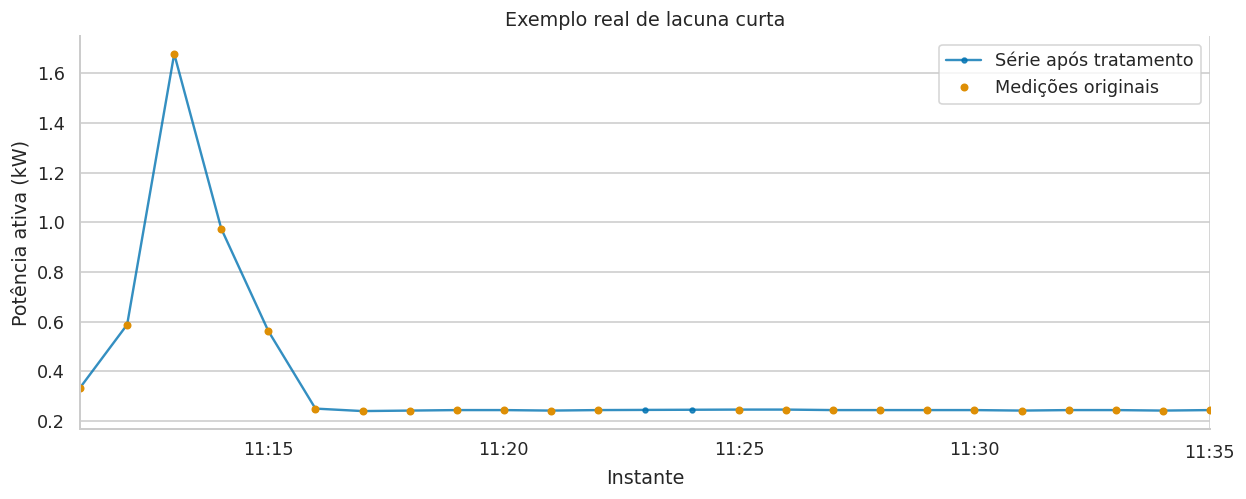

**Análise dos resultados.** Foram estimados 76 minutos de potência ativa. Permanecem 25.903 minutos sem valor. A preservação das lacunas longas impedirá que períodos desconhecidos sejam classificados como baixo consumo.

In [6]:
potencia_original_valida = dados['potencia_kw'].notna()

def interpolar_lacunas_curtas(serie, max_lacuna=5):
    ausente = serie.isna()
    grupos = ausente.ne(ausente.shift(fill_value=False)).cumsum()
    tamanho = ausente.groupby(grupos).transform('size')
    permitida = ausente & tamanho.le(max_lacuna)
    estimativa = serie.interpolate(method='time', limit_area='inside')
    return serie.mask(permitida, estimativa)

tratados = dados.copy()
auditoria_imputacao = []
for coluna in tratados.columns:
    antes = int(tratados[coluna].isna().sum())
    tratados[coluna] = interpolar_lacunas_curtas(tratados[coluna], MAX_LACUNA_MIN)
    depois = int(tratados[coluna].isna().sum())
    auditoria_imputacao.append([coluna, antes, antes-depois, depois])

auditoria_imputacao = pd.DataFrame(auditoria_imputacao,
    columns=['variavel', 'ausentes_antes', 'preenchidos', 'ausentes_depois']).set_index('variavel')
potencia_imputada = ~potencia_original_valida & tratados['potencia_kw'].notna()
display(auditoria_imputacao)

if potencia_imputada.any():
    centro = potencia_imputada[potencia_imputada].index[0]
    janela = slice(centro-pd.Timedelta(minutes=12), centro+pd.Timedelta(minutes=12))
    ax = tratados.loc[janela, 'potencia_kw'].plot(label='Série após tratamento', marker='.', alpha=.8)
    dados.loc[janela, 'potencia_kw'].plot(ax=ax, linestyle='none', marker='o',
                                      label='Medições originais', markersize=4)
    ax.set(ylabel='Potência ativa (kW)', xlabel='Instante', title='Exemplo real de lacuna curta')
    ax.legend()
    plt.tight_layout(); plt.show()
analise(f'Foram estimados {br(potencia_imputada.sum(), 0)} minutos de potência ativa. '
        f'Permanecem {br(tratados.potencia_kw.isna().sum(), 0)} minutos sem valor. '
        'A preservação das lacunas longas impedirá que períodos desconhecidos sejam classificados como baixo consumo.')

**Explicação do algoritmo**

`ausente` indica as posições sem medição. A mudança entre presença e ausência inicia um novo grupo, identificado pela soma acumulada. `transform('size')` associa a cada posição o comprimento de sua sequência. A máscara `permitida` seleciona apenas lacunas inteiras que respeitam o limite.

A interpolação usa as distâncias temporais e `limit_area='inside'` impede extrapolação nas extremidades. `mask` copia estimativas apenas para as lacunas permitidas. A auditoria contabiliza antes, preenchimento e depois por variável. O gráfico diferencia valores observados e a curva tratada; os indicadores de imputação permanecem disponíveis para avaliar sua influência.

## 7. Agregação temporal e seleção de dias comparáveis

Potência é uma taxa de transferência de energia. Como a potência ativa é uma média por minuto, a energia do intervalo é $E_t=P_t\times(1/60)$ kWh. Para um dia completo, $E_d=\sum_{t=1}^{1440}P_t/60$. Somar kW diretamente sem multiplicar pela duração produz uma grandeza incorreta.

O pico de 15 minutos será o maior valor entre as médias de blocos fixos de 15 minutos do dia. Essa medida permite estudar demanda em uma escala operacional definida. Ela não é o pico instantâneo, nem comprova a demanda utilizada por uma regra tarifária específica.

Um dia só entrará no conjunto principal quando tiver potência disponível em todos os minutos após o preenchimento permitido e cobertura original mínima de 98%. Dias parciais no início ou fim da série serão excluídos. As exclusões serão avaliadas por mês para revelar alterações na composição temporal da amostra.

In [7]:
p = tratados['potencia_kw'].astype('float64')
qualidade = pd.DataFrame({
    'minutos_originais': potencia_original_valida.resample('D').sum(),
    'minutos_disponiveis': p.resample('D').count(),
    'minutos_imputados': potencia_imputada.resample('D').sum()
})
qualidade['cobertura_original'] = qualidade.minutos_originais / 1440
qualidade['aceito'] = (qualidade.minutos_disponiveis.eq(1440) &
                       qualidade.cobertura_original.ge(COBERTURA_ORIGINAL_MIN))

p15 = p.resample('15min').mean().where(p.resample('15min').count().eq(15))
energia_dia = p.resample('D').sum(min_count=1440) / 60
diario = pd.DataFrame({
    'energia_kwh': energia_dia,
    'pico_15min_kw': p15.resample('D').max(),
    'potencia_media_kw': p.resample('D').mean(),
    'pico_1min_kw': p.resample('D').max(),
    'tensao_media_v': tratados.tensao_v.resample('D').mean(),
    'corrente_media_a': tratados.corrente_a.resample('D').mean()
}).loc[qualidade.aceito].copy()

p_hora = p.resample('h').mean().where(p.resample('h').count().eq(60))
horario = pd.DataFrame({'data': p_hora.index.normalize(),
                        'hora': p_hora.index.hour, 'potencia_kw': p_hora.to_numpy()})
curvas = horario.pivot(index='data', columns='hora', values='potencia_kw').reindex(diario.index)
assert curvas.shape[1] == 24 and curvas.notna().all().all()
assert np.allclose(curvas.sum(axis=1), diario.energia_kwh)

auditoria_mensal = qualidade.resample('MS').agg(dias=('aceito', 'size'),
                                               aceitos=('aceito', 'sum'))
auditoria_mensal['retencao_%'] = 100 * auditoria_mensal.aceitos / auditoria_mensal.dias
display(qualidade.agg({'minutos_originais': 'sum', 'minutos_imputados': 'sum',
                      'aceito': 'sum'}).to_frame('Total'))
display(auditoria_mensal.sort_values('retencao_%').head(6))
analise(f'Foram retidos {br(len(diario), 0)} de {br(len(qualidade), 0)} dias '
        f'({br(100*len(diario)/len(qualidade))}%). A energia diária agora corresponde a '
        '24 horas completas, incluindo apenas as estimativas curtas autorizadas. '
        'Os meses com menor retenção exigem cautela nas comparações sazonais.')

,Total
minutos_originais,2049280
minutos_imputados,76
aceito,1410


,dias,aceitos,retencao_%
instante,,,
2010-08-01,31,25,80.645
2010-09-01,30,26,86.667
2007-04-01,30,27,90.000
2009-06-01,30,27,90.000
2010-01-01,31,28,90.323
2009-02-01,28,26,92.857


**Análise dos resultados.** Foram retidos 1.410 de 1.442 dias (97,78%). A energia diária agora corresponde a 24 horas completas, incluindo apenas as estimativas curtas autorizadas. Os meses com menor retenção exigem cautela nas comparações sazonais.

**Explicação do algoritmo**

`resample` reúne medições em intervalos temporais. A contagem diária verifica completude; a soma com `min_count=1440` retorna ausência quando faltam valores, em vez de apresentar uma energia parcial. O cálculo em 64 bits reduz erros de acumulação.

As médias de 15 minutos só são aceitas com 15 valores. As médias horárias exigem 60 valores e são reorganizadas em uma matriz com um dia por linha e uma hora por coluna. Como cada coluna representa uma hora, a soma das 24 potências médias equivale numericamente à energia diária em kWh. A asserção verifica essa identidade e a correspondência entre as tabelas. A auditoria mensal registra a população observada após o filtro.

## 8. Indicadores elétricos e balanço entre circuitos

O fator de carga compara o aproveitamento médio com a demanda máxima considerada: $FC_d=P_{\text{média},d}/P_{\text{máxima de 15 min},d}$. Valores próximos de 1 indicam uma curva relativamente uniforme; valores menores indicam concentração da demanda. Esse indicador não é fator de potência.

A participação de uma janela é sua energia dividida pela energia diária. Serão calculadas as frações de 00h a 06h e de 18h a 22h. As submedições já representam energia em Wh por minuto e devem ser somadas e divididas por 1.000 para obter kWh. O consumo residual é a energia total menos as três submedições, conforme a definição da base. Pequenos resíduos negativos podem refletir resolução ou sincronização dos instrumentos e serão contabilizados, sem truncamento automático.

,energia_kwh,pico_15min_kw,fator_carga,fracao_madrugada,fracao_noite
instante,,,,,
2006-12-17,56.508,5.126,0.459,0.225,0.230
2006-12-18,36.730,3.899,0.392,0.068,0.279
2006-12-19,27.770,6.590,0.176,0.089,0.304
2006-12-20,37.096,5.524,0.280,0.064,0.359
2006-12-21,28.619,3.797,0.314,0.176,0.282


,energia_kwh,participacao_%
Cozinha,2279.403,6.170
Lavanderia,2641.222,7.149
Aquecimento e climatização,13120.591,35.514
Demais cargas / resíduo,18903.480,51.167


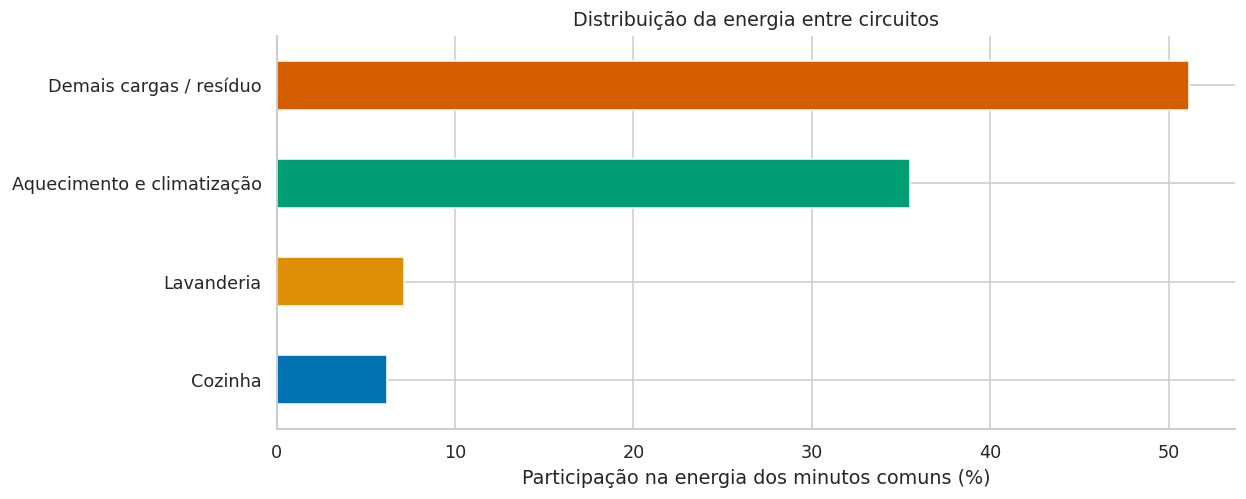

**Análise dos resultados.** O fator de carga mediano foi 0,28, equivalente a um pico de 15 minutos de aproximadamente 3,57 vezes a potência média nesse patamar de fator de carga. O circuito de aquecimento e climatização respondeu por 35,51% da energia nos minutos comuns. Foram encontrados 1.059 resíduos minutais negativos; eles registram discrepâncias de balanço, não geração comprovada. A submedição agrega equipamentos e não permite identificar qual deles operou em cada minuto.

In [8]:
diario['fator_carga'] = diario.potencia_media_kw / diario.pico_15min_kw
diario['fracao_madrugada'] = curvas.loc[:, range(0, 6)].sum(axis=1) / diario.energia_kwh
diario['fracao_noite'] = curvas.loc[:, HORAS_NOITE].sum(axis=1) / diario.energia_kwh
diario['dia_semana'] = diario.index.dayofweek
diario['fim_semana'] = diario.dia_semana.ge(5)
diario['mes'] = diario.index.month
diario['ano'] = diario.index.year
diario['minutos_imputados'] = qualidade.loc[diario.index, 'minutos_imputados']

cols_sub = ['cozinha_wh', 'lavanderia_wh', 'aquecimento_climatizacao_wh']
minutos_aceitos = tratados.index.normalize().isin(diario.index)
comuns = tratados.loc[minutos_aceitos, ['potencia_kw', *cols_sub]].dropna().astype('float64')
energia_total_wh = comuns.potencia_kw * 1000 / 60
residuo_wh = energia_total_wh - comuns[cols_sub].sum(axis=1)
balanco = pd.Series({
    'Cozinha': comuns.cozinha_wh.sum()/1000,
    'Lavanderia': comuns.lavanderia_wh.sum()/1000,
    'Aquecimento e climatização': comuns.aquecimento_climatizacao_wh.sum()/1000,
    'Demais cargas / resíduo': residuo_wh.sum()/1000
}, name='energia_kwh').to_frame()
balanco['participacao_%'] = balanco.energia_kwh / (energia_total_wh.sum()/1000) * 100
display(diario[['energia_kwh', 'pico_15min_kw', 'fator_carga',
                 'fracao_madrugada', 'fracao_noite']].head())
display(balanco)
balanco['participacao_%'].plot.barh(color=sns.color_palette('colorblind')[:4])
plt.xlabel('Participação na energia dos minutos comuns (%)')
plt.title('Distribuição da energia entre circuitos'); plt.tight_layout(); plt.show()
analise(f'O fator de carga mediano foi {br(diario.fator_carga.median())}, '
        f'equivalente a um pico de 15 minutos de aproximadamente '
        f'{br(1/diario.fator_carga.median())} vezes a potência média nesse patamar de fator de carga. '
        f'O circuito de aquecimento e climatização respondeu por '
        f'{br(balanco.loc["Aquecimento e climatização", "participacao_%"])}% da energia '
        f'nos minutos comuns. Foram encontrados {br(residuo_wh.lt(0).sum(), 0)} resíduos '
        'minutais negativos; eles registram discrepâncias de balanço, não geração comprovada. '
        'A submedição agrega equipamentos e não permite identificar qual deles operou em cada minuto.')
del comuns

**Explicação do algoritmo**

As frações horárias usam a soma das potências médias de intervalos de uma hora. O denominador é a energia do mesmo dia, garantindo compatibilidade temporal. As variáveis de calendário serão usadas para explicar os grupos, sem entrar na formação deles.

O balanço considera apenas instantes em que todos os canais necessários estão disponíveis. Isso evita comparar uma submedição de período incompleto com um total de período completo. A coluna residual é calculada antes da soma e preserva diferenças negativas para auditoria. A tabela de participações utiliza exatamente o mesmo conjunto de minutos no numerador e no denominador.

## 9. Estatística descritiva: nível, dispersão e assimetria

A média resume o nível central, mas é sensível a extremos. A mediana divide as observações ordenadas ao meio e representa melhor o centro quando a distribuição é assimétrica. O desvio padrão mede dispersão em torno da média; o intervalo interquartil resume os 50% centrais. O percentil 95 informa um patamar excedido em aproximadamente 5% dos dias analisados.

O histograma mostra concentração e caudas. O boxplot destaca mediana, quartis e observações além dos limites de Tukey. Uma cauda à direita indica alguns dias com valores elevados, o que é relevante para demanda e capacidade. Nenhuma dessas medidas, isoladamente, identifica a causa física de uma ocorrência.

,count,mean,std,min,5%,25%,50%,75%,95%,max,IQR,assimetria
energia_kwh,1410.0,26.202,10.009,4.172,9.185,19.671,25.937,31.669,43.988,79.556,11.998,0.566
pico_15min_kw,1410.0,3.929,1.405,0.359,1.552,3.067,3.873,4.736,6.404,8.566,1.670,0.173
fator_carga,1410.0,0.285,0.067,0.097,0.185,0.239,0.280,0.323,0.407,0.588,0.084,0.522


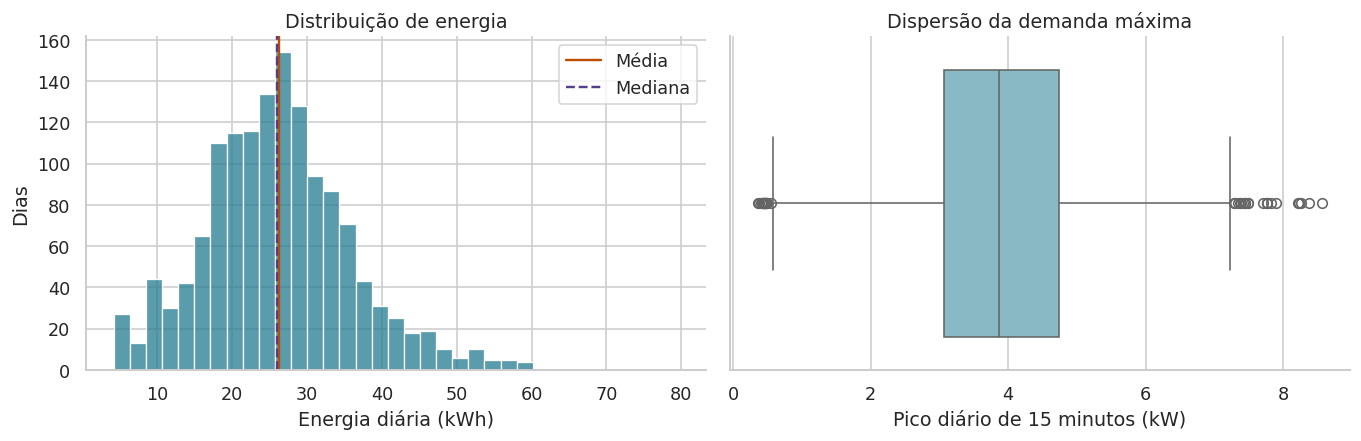

**Análise dos resultados.** O consumo médio foi 26,20 kWh/dia e a mediana 25,94 kWh/dia. Em 95% dos dias, a energia ficou em até 43,99 kWh. O percentil 95 do pico de 15 minutos foi 6,40 kW. Esses valores descrevem a residência e o período retido; a média diária não substitui a análise dos picos.

In [9]:
variaveis_descr = ['energia_kwh', 'pico_15min_kw', 'fator_carga']
estatisticas = diario[variaveis_descr].describe(percentiles=[.05, .25, .5, .75, .95]).T
estatisticas['IQR'] = estatisticas['75%'] - estatisticas['25%']
estatisticas['assimetria'] = diario[variaveis_descr].skew()
display(estatisticas)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(diario.energia_kwh, bins=35, ax=eixos[0], color='#247b91')
eixos[0].axvline(diario.energia_kwh.mean(), color='#bb4d00', label='Média')
eixos[0].axvline(diario.energia_kwh.median(), color='#543e8b', ls='--', label='Mediana')
eixos[0].set(xlabel='Energia diária (kWh)', ylabel='Dias', title='Distribuição de energia')
eixos[0].legend()
sns.boxplot(x=diario.pico_15min_kw, ax=eixos[1], color='#80bfd0')
eixos[1].set(xlabel='Pico diário de 15 minutos (kW)', title='Dispersão da demanda máxima')
plt.tight_layout(); plt.show()
analise(f'O consumo médio foi {br(diario.energia_kwh.mean())} kWh/dia e a mediana '
        f'{br(diario.energia_kwh.median())} kWh/dia. Em 95% dos dias, a energia ficou '
        f'em até {br(diario.energia_kwh.quantile(.95))} kWh. O percentil 95 do pico de '
        f'15 minutos foi {br(diario.pico_15min_kw.quantile(.95))} kW. Esses valores '
        'descrevem a residência e o período retido; a média diária não substitui a análise dos picos.')

**Explicação do algoritmo**

`describe` reúne contagem, média, desvio padrão, extremos e percentis. A transposição coloca as grandezas nas linhas, facilitando a leitura de unidades distintas. O IQR é calculado pela diferença entre os quartis e `skew` quantifica a assimetria.

O histograma utiliza energia diária, enquanto o boxplot utiliza demanda máxima de 15 minutos. As linhas verticais destacam média e mediana sobre a mesma distribuição. Comparar gráficos de grandezas diferentes permite separar consumo acumulado de solicitação máxima da instalação.

## 10. Padrões horários e variações no calendário

Uma curva média diária indica em quais horários a residência costuma consumir mais. Entretanto, a média pode esconder diferenças entre dias. Por isso, serão representados também os quartis horários e as curvas de dias de segunda a sexta e de fins de semana. A categoria de segunda a sexta não desconta feriados, pois não foi incorporado um calendário local.

O comportamento mensal será examinado pela energia média diária, evitando comparar totais de meses com quantidades diferentes de dias. Alterações ao longo do ano podem refletir clima, ocupação e hábitos; esta base não contém variáveis suficientes para atribuir causalmente uma mudança a esses fatores.

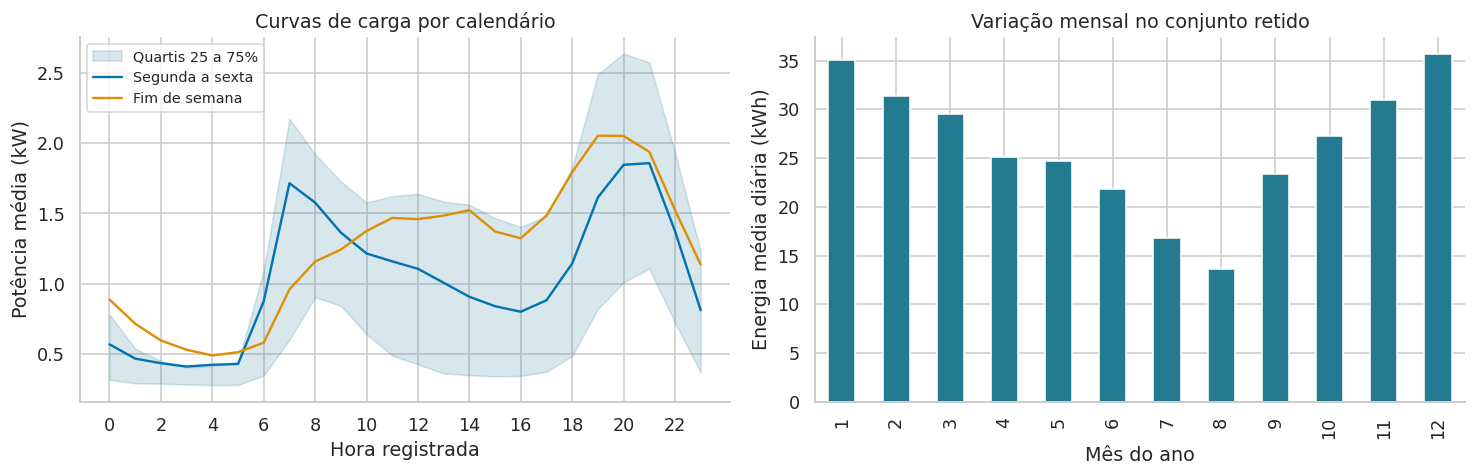

,media_kwh_dia,mediana_kwh_dia,dias
mes,,,
1,35.073,34.059,121
2,31.374,31.337,111
3,29.553,29.648,122
4,25.157,25.647,117
5,24.710,25.083,124
6,21.870,21.219,116
7,16.809,17.111,123
8,13.632,12.845,116
9,23.408,22.993,116


**Análise dos resultados.** A curva média atingiu seu maior valor às 20h, com 1,90 kW. O mês 12 apresentou a maior média diária (35,65 kWh), enquanto o mês 8 apresentou a menor (13,63 kWh). Esses contrastes justificam considerar horário e sazonalidade na interpretação dos perfis; não identificam, sozinhos, a causa da variação.

In [10]:
curva_media = curvas.mean()
curva_q25, curva_q75 = curvas.quantile(.25), curvas.quantile(.75)
curva_semana = curvas.loc[~diario.fim_semana].mean()
curva_fds = curvas.loc[diario.fim_semana].mean()
mensal = diario.groupby('mes').energia_kwh.agg(['mean', 'median', 'count'])

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.3))
eixos[0].fill_between(range(24), curva_q25, curva_q75, alpha=.18, color='#247b91', label='Quartis 25 a 75%')
eixos[0].plot(range(24), curva_semana, label='Segunda a sexta')
eixos[0].plot(range(24), curva_fds, label='Fim de semana')
eixos[0].set(xlabel='Hora registrada', ylabel='Potência média (kW)', title='Curvas de carga por calendário', xticks=range(0,24,2))
eixos[0].legend(fontsize=9)
mensal['mean'].plot.bar(ax=eixos[1], color='#247b91')
eixos[1].set(xlabel='Mês do ano', ylabel='Energia média diária (kWh)', title='Variação mensal no conjunto retido')
plt.tight_layout(); plt.show()
display(mensal.rename(columns={'mean':'media_kwh_dia', 'median':'mediana_kwh_dia', 'count':'dias'}))
hora_max = int(curva_media.idxmax())
mes_max, mes_min = int(mensal['mean'].idxmax()), int(mensal['mean'].idxmin())
analise(f'A curva média atingiu seu maior valor às {hora_max:02d}h, com '
        f'{br(curva_media.max())} kW. O mês {mes_max} apresentou a maior média diária '
        f'({br(mensal.loc[mes_max,"mean"])} kWh), enquanto o mês {mes_min} apresentou '
        f'a menor ({br(mensal.loc[mes_min,"mean"])} kWh). Esses contrastes justificam '
        'considerar horário e sazonalidade na interpretação dos perfis; não identificam, sozinhos, a causa da variação.')

**Explicação do algoritmo**

A matriz de curvas fornece médias e quantis por coluna, isto é, por hora. A faixa interquartil mostra a variabilidade entre dias e não um intervalo de confiança da média. As máscaras de calendário selecionam os dias antes de calcular as curvas de cada categoria.

O agrupamento pelo número do mês reúne os anos disponíveis. A contagem informa quantos dias sustentam cada média, pois o período inicial e final e as exclusões alteram a representação dos meses. Essa comparação descreve uma composição histórica de anos, sem separar automaticamente efeitos de tendência e sazonalidade.

## 11. Associações estatísticas e redundância entre variáveis

A correlação de Pearson mede associação linear. A correlação de Spearman aplica a correlação aos postos e identifica associações monotônicas, reduzindo a influência da escala e de valores extremos. Seus coeficientes variam entre −1 e 1. Próximo de zero significa pouca associação do tipo medido, sem excluir relações mais complexas.

Energia diária e corrente média podem apresentar associação elevada porque descrevem grandezas eletricamente relacionadas. Energia e potência média diária são exatamente proporcionais em dias de 24 horas; incluir ambas em um algoritmo de distância daria peso duplicado à mesma informação. Correlação ajuda a diagnosticar redundância e a formular hipóteses, mas não estabelece causalidade.

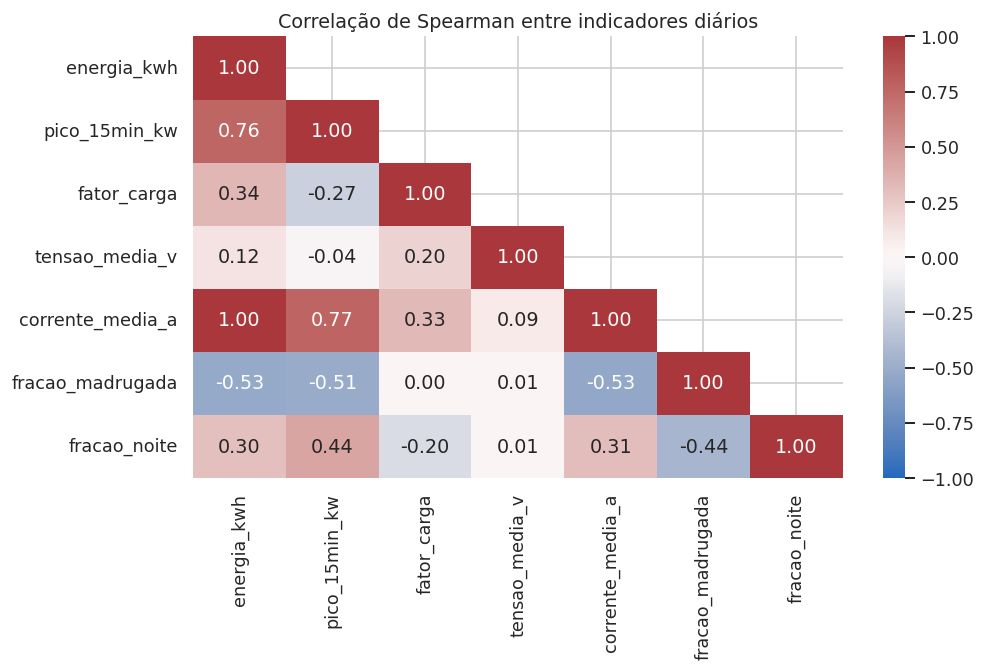

,Pearson com energia,Spearman com energia
energia_kwh,1.000,1.000
pico_15min_kw,0.774,0.761
fator_carga,0.322,0.341
tensao_media_v,0.118,0.121
corrente_media_a,0.999,0.999
fracao_madrugada,-0.364,-0.528
fracao_noite,0.258,0.302


**Análise dos resultados.** A correlação de Spearman entre energia e corrente média foi 0,9988; entre energia e pico de 15 minutos foi 0,76. Essa associação mostra que indicadores diferentes compartilham informação. A segmentação evitará incluir simultaneamente energia e potência média, mantendo indicadores de nível e distribuição temporal.

In [11]:
cols_corr = ['energia_kwh', 'pico_15min_kw', 'fator_carga', 'tensao_media_v',
             'corrente_media_a', 'fracao_madrugada', 'fracao_noite']
corr_pearson = diario[cols_corr].corr(method='pearson')
corr_spearman = diario[cols_corr].corr(method='spearman')
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(corr_spearman, vmin=-1, vmax=1, center=0, cmap='vlag', annot=True,
            fmt='.2f', mask=np.triu(np.ones_like(corr_spearman, dtype=bool), k=1), ax=ax)
ax.set_title('Correlação de Spearman entre indicadores diários')
plt.tight_layout(); plt.show()
display(pd.DataFrame({
    'Pearson com energia': corr_pearson.energia_kwh,
    'Spearman com energia': corr_spearman.energia_kwh
}))
analise(f'A correlação de Spearman entre energia e corrente média foi '
        f'{br(corr_spearman.loc["energia_kwh","corrente_media_a"],4)}; entre energia e '
        f'pico de 15 minutos foi {br(corr_spearman.loc["energia_kwh","pico_15min_kw"])}. '
        'Essa associação mostra que indicadores diferentes compartilham informação. '
        'A segmentação evitará incluir simultaneamente energia e potência média, mantendo indicadores de nível e distribuição temporal.')

**Explicação do algoritmo**

As duas matrizes são calculadas sobre os mesmos dias. A máscara triangular remove a repetição visual dos pares, pois uma correlação de A com B é igual à correlação de B com A. A diagonal permanece igual a 1 por representar uma variável comparada consigo mesma.

A tabela destaca as associações com energia para permitir a comparação entre Pearson e Spearman. Diferenças entre os coeficientes podem sugerir não linearidade monotônica ou influência de extremos, mas exigem inspeção adicional. A seleção de atributos combina esse diagnóstico com o significado elétrico de cada indicador.

## 12. Diferença entre fins de semana e dias de semana: incerteza temporal

Comparar duas médias sem considerar a ordem dos dias pode subestimar a incerteza. Observações próximas compartilham condições de ocupação e época do ano. Será calculada, em cada semana completa, a diferença entre a energia média de sábado e domingo e a média de segunda a sexta: $\Delta_w=\bar{E}_{\text{fim de semana},w}-\bar{E}_{\text{segunda a sexta},w}$.

A comparação dentro da mesma semana reduz diferenças lentas de calendário. Para expressar incerteza, será empregado **bootstrap em blocos móveis**: sorteiam-se trechos consecutivos de semanas, com reposição, e recalcula-se a média das diferenças. Os percentis 2,5 e 97,5 das réplicas formam um intervalo percentil de 95%. Blocos de 4 e 12 semanas permitem observar sensibilidade à dependência temporal.

O procedimento é exploratório: pressupõe que os blocos observados representem o processo de interesse. Tendências, mudanças de ocupação e sazonalidade forte limitam essa aproximação. O resultado refere-se à diferença média entre semanas completas desta residência, com o mesmo peso para cada semana.

In [12]:
sem = diario[['energia_kwh', 'fim_semana']].copy()
sem['semana'] = sem.index.to_period('W-SUN')
medias_sem = sem.groupby(['semana', 'fim_semana']).energia_kwh.mean().unstack()
contagens_sem = sem.groupby(['semana', 'fim_semana']).energia_kwh.count().unstack()
completas = contagens_sem[False].eq(5) & contagens_sem[True].eq(2)
diferencas = (medias_sem[True] - medias_sem[False]).where(completas)
calendario_sem = pd.period_range(sem.semana.min(), sem.semana.max(), freq='W-SUN')
diferencas = diferencas.reindex(calendario_sem)

def bootstrap_blocos(valores, tamanho_bloco, repeticoes=2000, semente=42):
    rng = np.random.default_rng(semente)
    valores = np.asarray(valores, dtype=float)
    n = len(valores)
    n_blocos = int(np.ceil(n / tamanho_bloco))
    estimativas = np.empty(repeticoes)
    for b in range(repeticoes):
        inicios = rng.integers(0, n-tamanho_bloco+1, size=n_blocos)
        indices = (inicios[:, None] + np.arange(tamanho_bloco)).ravel()[:n]
        estimativas[b] = np.nanmean(valores[indices])
    return np.quantile(estimativas, [.025, .975])

resultados_boot = []
for tamanho in [4, 12]:
    inferior, superior = bootstrap_blocos(diferencas, tamanho)
    resultados_boot.append([tamanho, diferencas.mean(), inferior, superior])
tabela_boot = pd.DataFrame(resultados_boot, columns=['bloco_semanas', 'diferenca_kwh', 'IC95_inferior', 'IC95_superior'])
display(tabela_boot)
ic = tabela_boot.iloc[0]
leitura_ic = ('inclui zero e é compatível com diferenças médias de ambos os sinais'
              if ic.IC95_inferior <= 0 <= ic.IC95_superior
              else 'não inclui zero sob as hipóteses desta reamostragem')
analise(f'Em {br(diferencas.notna().sum(), 0)} semanas completas, a diferença média foi '
        f'{br(diferencas.mean())} kWh/dia. O intervalo com blocos de quatro semanas '
        f'vai de {br(ic.IC95_inferior)} a {br(ic.IC95_superior)} kWh e {leitura_ic}. '
        'A segunda linha mostra o efeito de preservar dependência por mais semanas. '
        'Trata-se de uma associação de calendário, sem demonstração de efeito causal do fim de semana.')

,bloco_semanas,diferenca_kwh,IC95_inferior,IC95_superior
0,4,4.732,3.563,5.972
1,12,4.732,3.135,6.169


**Análise dos resultados.** Em 187 semanas completas, a diferença média foi 4,73 kWh/dia. O intervalo com blocos de quatro semanas vai de 3,56 a 5,97 kWh e não inclui zero sob as hipóteses desta reamostragem. A segunda linha mostra o efeito de preservar dependência por mais semanas. Trata-se de uma associação de calendário, sem demonstração de efeito causal do fim de semana.

**Explicação do algoritmo**

O período `W-SUN` define semanas de segunda a domingo. As tabelas de contagem exigem cinco dias de segunda a sexta e dois dias de fim de semana válidos. Semanas incompletas recebem ausência; a reindexação preserva sua posição no calendário, impedindo que semanas distantes se tornem artificialmente vizinhas.

Em cada repetição, o algoritmo sorteia inícios de blocos, constrói índices consecutivos e concatena trechos até atingir o comprimento original. `nanmean` usa diferenças disponíveis sem preencher semanas ausentes. Os intervalos resultam da distribuição empírica das médias reamostradas. A semente fixa os sorteios e os dois comprimentos avaliam uma escolha metodológica que não pode ser determinada apenas pelo número de observações.

## 13. Construção da representação para agrupamento

Um algoritmo de agrupamento recebe números e uma regra de proximidade. A representação precisa traduzir o problema: deseja-se distinguir dias pelo nível de consumo, uniformidade da demanda e distribuição entre janelas horárias. Serão usados quatro atributos: energia diária, fator de carga, participação da madrugada e participação das 18h às 22h. As frações não cobrem todo o dia e, portanto, não somam obrigatoriamente 1.

A energia será transformada por $\log(1+E)$. A transformação reduz o peso relativo de diferenças absolutas em dias muito energéticos, sem eliminar os extremos. Em seguida, cada atributo será padronizado por $z_{ij}=(x_{ij}-\mu_j)/\sigma_j$. Assim, uma diferença de um desvio padrão terá a mesma escala numérica em cada coluna.

Padronizar não torna as distribuições normais e não elimina correlações. A escolha atribui pesos iguais às colunas padronizadas; isso é uma decisão de modelagem. Os valores originais serão mantidos para interpretação. Calendário, identificadores de data e indicadores de qualidade ficam fora da formação dos grupos.

In [13]:
atributos = pd.DataFrame({
    'log_energia': np.log1p(diario.energia_kwh),
    'fator_carga': diario.fator_carga,
    'fracao_madrugada': diario.fracao_madrugada,
    'fracao_noite': diario.fracao_noite
}, index=diario.index)
assert np.isfinite(atributos.to_numpy()).all()
assert atributos.std().gt(0).all()

padronizador = StandardScaler()
X = padronizador.fit_transform(atributos)
X_df = pd.DataFrame(X, index=atributos.index, columns=atributos.columns)
display(pd.DataFrame({'media_antes': atributos.mean(), 'desvio_antes': atributos.std(ddof=0),
                      'media_depois': X_df.mean(), 'desvio_depois': X_df.std(ddof=0)}))
display(X_df.head())
analise(f'Cada um dos {br(len(X), 0)} dias foi representado por quatro atributos. '
        'Após a padronização, as médias ficam próximas de zero e os desvios padrão de um. '
        'As distâncias passam a combinar consumo, fator de carga e distribuição horária, '
        'sem serem dominadas apenas pela unidade kWh.')

,media_antes,desvio_antes,media_depois,desvio_depois
log_energia,3.226,0.419,-1.728e-15,1.0
fator_carga,0.285,0.067,2.016e-17,1.0
fracao_madrugada,0.125,0.071,1.159e-16,1.0
fracao_noite,0.253,0.085,4.031e-17,1.0


,log_energia,fator_carga,fracao_madrugada,fracao_noite
instante,,,,
2006-12-17,1.972,2.609,1.404,-0.267
2006-12-18,0.966,1.609,-0.805,0.303
2006-12-19,0.318,-1.637,-0.516,0.595
2006-12-20,0.989,-0.077,-0.867,1.243
2006-12-21,0.388,0.435,0.723,0.337


**Análise dos resultados.** Cada um dos 1.410 dias foi representado por quatro atributos. Após a padronização, as médias ficam próximas de zero e os desvios padrão de um. As distâncias passam a combinar consumo, fator de carga e distribuição horária, sem serem dominadas apenas pela unidade kWh.

**Explicação do algoritmo**

`log1p` calcula o logaritmo natural de um mais a energia. A tabela `atributos` reúne exclusivamente as variáveis escolhidas, na ordem que será preservada no modelo. As asserções verificam valores finitos e ausência de colunas constantes antes do ajuste.

`fit_transform` estima médias e desvios e aplica a transformação. A conferência usa `ddof=0`, consistente com `StandardScaler`. Esta análise descreve o conjunto histórico inteiro, portanto o ajuste usa todos os dias. Para classificar dias futuros, o padronizador deve ser congelado e aplicado com `transform`; uma avaliação prospectiva exigiria separação temporal antes de qualquer ajuste.

## 14. PCA para visualizar uma representação multidimensional

A análise de componentes principais, PCA, encontra combinações lineares ortogonais que retêm a maior variância possível. Após centralizar os dados, uma componente tem a forma $PC_k=\sum_j w_{kj}z_j$. Os coeficientes indicam a participação das variáveis na direção, e a variância explicada quantifica quanta dispersão original permanece em cada eixo.

O PCA será utilizado para visualização. Os agrupamentos serão ajustados nos quatro atributos padronizados, mantendo a informação que uma projeção em dois eixos descartaria. Pontos próximos no gráfico podem estar separados nas dimensões omitidas. O sinal de uma componente é arbitrário: inverter todos os seus coeficientes preserva a mesma direção geométrica.

,PC1,PC2
log_energia,-0.531,0.453
fator_carga,0.083,0.844
fracao_madrugada,0.624,0.013
fracao_noite,-0.567,-0.286


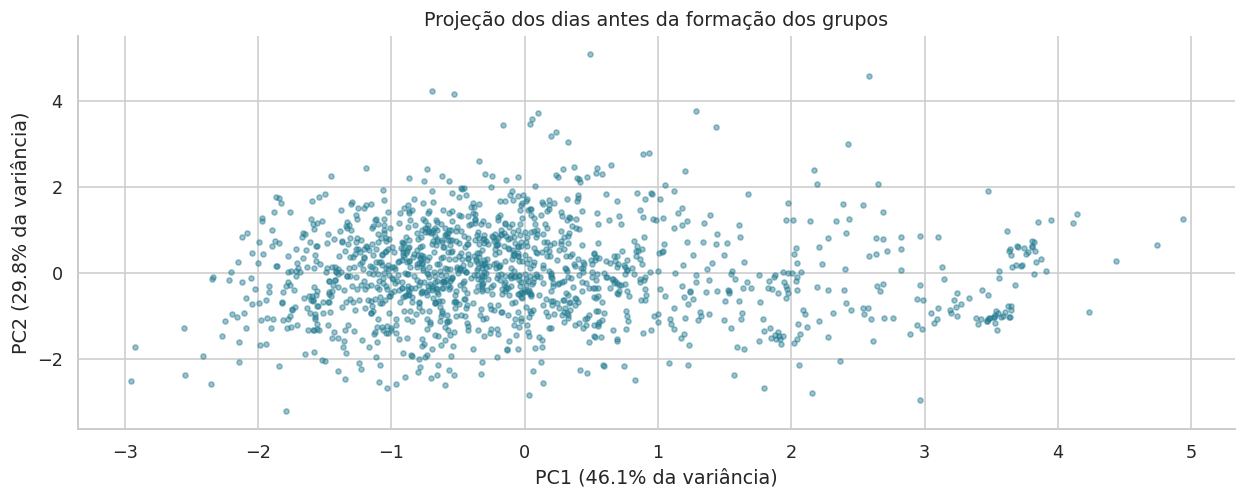

**Análise dos resultados.** Os dois eixos preservam 75,90% da variância padronizada. Os 24,10% restantes ficam fora do gráfico. A nuvem permite examinar estrutura e continuidade, mas ainda não atribui grupos nem demonstra separação entre regimes operacionais.

In [14]:
pca = PCA(n_components=2, svd_solver='full')
projecao = pca.fit_transform(X)
variancia_2d = pca.explained_variance_ratio_.sum()
coeficientes_pca = pd.DataFrame(pca.components_.T, index=atributos.columns,
                               columns=['PC1', 'PC2'])
display(coeficientes_pca)
plt.scatter(projecao[:, 0], projecao[:, 1], s=10, alpha=.45, color='#247b91')
plt.xlabel(f'PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% da variância)')
plt.ylabel(f'PC2 ({100*pca.explained_variance_ratio_[1]:.1f}% da variância)')
plt.title('Projeção dos dias antes da formação dos grupos')
plt.tight_layout(); plt.show()
analise(f'Os dois eixos preservam {br(100*variancia_2d)}% da variância padronizada. '
        f'Os {br(100*(1-variancia_2d))}% restantes ficam fora do gráfico. '
        'A nuvem permite examinar estrutura e continuidade, mas ainda não atribui grupos '
        'nem demonstra separação entre regimes operacionais.')

**Explicação do algoritmo**

`fit_transform` estima as direções de maior variância e projeta os dias nelas. `components_` fornece os coeficientes das combinações lineares, enquanto `explained_variance_ratio_` informa a fração de variância por eixo. A soma das duas frações quantifica a informação preservada pela visualização.

O gráfico recebe somente as coordenadas projetadas. A matriz `X` permanece intacta e será a entrada dos algoritmos de agrupamento. Assim, a facilidade de desenhar o resultado não altera a representação utilizada para calcular proximidade.

## 15. K-means e escolha do número de grupos

O K-means procura centroides que minimizem a soma das distâncias quadráticas dos pontos ao centro do próprio grupo: $J=\sum_{k=1}^{K}\sum_{i\in C_k}\|x_i-\mu_k\|^2$. O procedimento alterna duas etapas: atribui cada dia ao centro mais próximo e recalcula cada centro pela média dos dias atribuídos. As iterações terminam quando as posições se estabilizam ou um limite é atingido.

O número de grupos precisa ser definido. A inércia sempre tende a diminuir quando K aumenta, de modo que o menor valor não identifica sozinho uma solução adequada. A silhueta compara a distância média de cada observação aos membros de seu grupo, $a(i)$, com a menor distância média a outro grupo, $b(i)$: $s(i)=[b(i)-a(i)]/\max[a(i),b(i)]$. Valores próximos de 1 indicam maior separação, próximos de zero indicam fronteiras sobrepostas e negativos sugerem uma atribuição pouco compatível com a geometria.

Serão avaliados K de 2 a 7. A escolha inicial maximiza a silhueta média, com desempate pelo menor K. Esse é um critério interno de exploração, não uma prova de que existam classes naturais ou de que o melhor K esteja necessariamente nesse intervalo.

,k,inercia,silhueta,davies_bouldin,menor_grupo
0,2,3902.245,0.413,1.143,251
1,3,3017.915,0.259,1.259,238
2,4,2545.549,0.251,1.205,177
3,5,2269.719,0.242,1.221,149
4,6,2056.022,0.250,1.119,24
5,7,1868.668,0.234,1.116,24


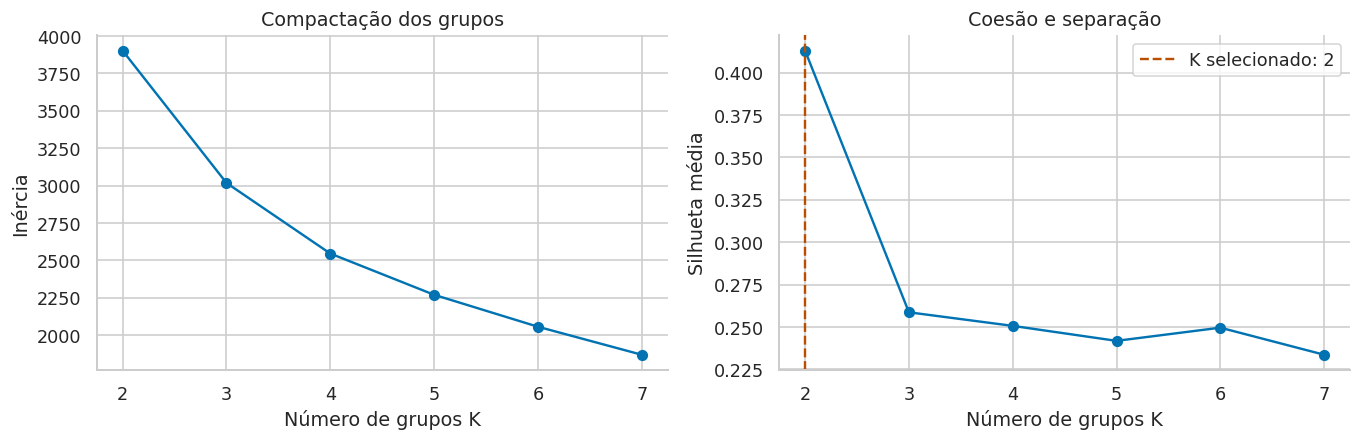

**Análise dos resultados.** O critério selecionou K=2, com silhueta média 0,413. A inércia mostra como a dispersão interna diminui, enquanto a silhueta penaliza soluções pouco separadas. O valor obtido deve ser combinado com tamanho, estabilidade e significado elétrico dos grupos; ele não representa acurácia.

In [15]:
avaliacao_k = []
modelos_k = {}
for k in range(2, 8):
    modelo = KMeans(n_clusters=k, init='k-means++', n_init=20,
                    max_iter=400, random_state=SEMENTE)
    rotulos = modelo.fit_predict(X)
    modelos_k[k] = modelo
    avaliacao_k.append({'k': k, 'inercia': modelo.inertia_,
                        'silhueta': silhouette_score(X, rotulos),
                        'davies_bouldin': davies_bouldin_score(X, rotulos),
                        'menor_grupo': np.bincount(rotulos).min()})
tabela_k = pd.DataFrame(avaliacao_k)
k_escolhido = int(tabela_k.sort_values(['silhueta', 'k'], ascending=[False, True]).iloc[0]['k'])
kmeans = modelos_k[k_escolhido]
rotulos_kmeans = kmeans.labels_

display(tabela_k)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
eixos[0].plot(tabela_k.k, tabela_k.inercia, 'o-')
eixos[0].set(xlabel='Número de grupos K', ylabel='Inércia', title='Compactação dos grupos')
eixos[1].plot(tabela_k.k, tabela_k.silhueta, 'o-')
eixos[1].axvline(k_escolhido, color='#bb4d00', ls='--', label=f'K selecionado: {k_escolhido}')
eixos[1].set(xlabel='Número de grupos K', ylabel='Silhueta média', title='Coesão e separação')
eixos[1].legend(); plt.tight_layout(); plt.show()
sil_k = silhouette_score(X, rotulos_kmeans)
analise(f'O critério selecionou K={k_escolhido}, com silhueta média {br(sil_k, 3)}. '
        'A inércia mostra como a dispersão interna diminui, enquanto a silhueta penaliza '
        'soluções pouco separadas. O valor obtido deve ser combinado com tamanho, estabilidade '
        'e significado elétrico dos grupos; ele não representa acurácia.')

**Explicação do algoritmo**

O laço ajusta um modelo para cada K. `k-means++` procura centros iniciais espalhados e `n_init=20` repete a inicialização, mantendo a solução de menor inércia. `max_iter` limita as atualizações e `random_state` controla a aleatoriedade.

`fit_predict` ajusta os centroides e devolve os rótulos. São registrados inércia, silhueta, índice Davies-Bouldin e tamanho do menor grupo. Davies-Bouldin compara dispersão interna e separação dos centros; valores menores são preferíveis nesse critério. A ordenação explicita a regra de seleção e o modelo escolhido é reaproveitado, sem um novo ajuste que pudesse produzir outros rótulos.

## 16. Diagnóstico das atribuições e estabilidade do K-means

A média da silhueta pode esconder dias ambíguos. O diagnóstico por observação identifica a proporção de valores negativos e permite comparar o comportamento dos grupos. Um grupo pequeno, embora legítimo, merece inspeção para verificar se representa um regime persistente ou apenas observações extremas.

A estabilidade será examinada repetindo o K-means com sementes diferentes. O índice de Rand ajustado, ARI, compara pares de observações colocados juntos ou separados em duas partições, descontando concordância esperada ao acaso. ARI igual a 1 indica partições equivalentes, mesmo que os números dos rótulos sejam diferentes. Essa verificação mede estabilidade de inicialização; não demonstra estabilidade em novos anos ou consumidores.

,semente,ARI_com_referencia
0,7,1.0
1,21,1.0
2,99,1.0
3,123,1.0
4,2026,1.0


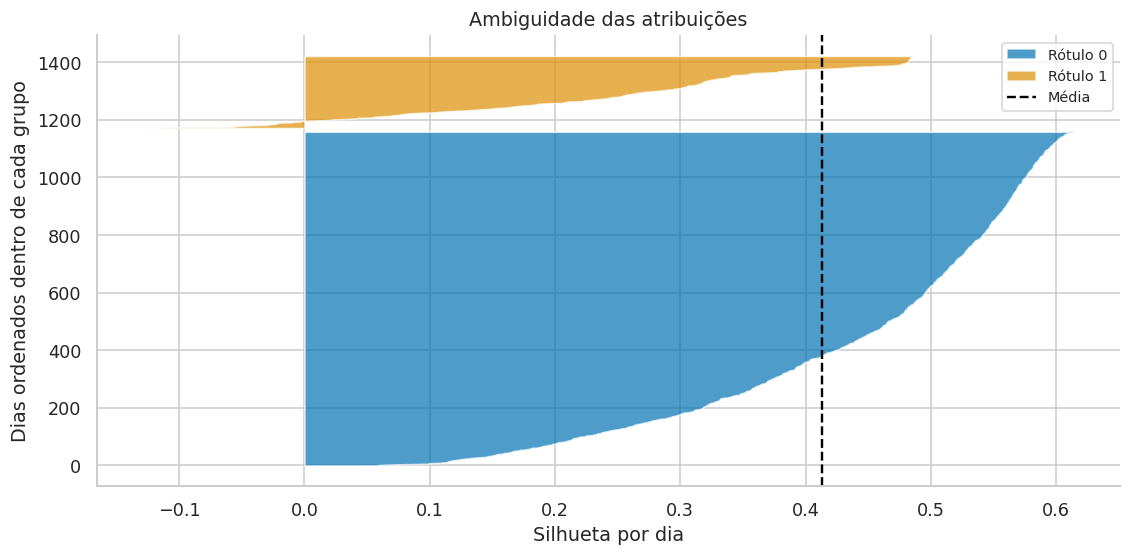

**Análise dos resultados.** 1,77% dos dias apresentaram silhueta negativa. O ARI entre inicializações variou de 1,000 a 1,000. Dias próximos às fronteiras exigem interpretação gradual; os rótulos não devem ser tratados como categorias físicas absolutas.

In [16]:
sil_individual = silhouette_samples(X, rotulos_kmeans)
estabilidade = []
for semente in [7, 21, 99, 123, 2026]:
    outros = KMeans(n_clusters=k_escolhido, n_init=20, max_iter=400,
                    random_state=semente).fit_predict(X)
    estabilidade.append([semente, adjusted_rand_score(rotulos_kmeans, outros)])
tabela_estabilidade = pd.DataFrame(estabilidade, columns=['semente', 'ARI_com_referencia'])
display(tabela_estabilidade)
fig, ax = plt.subplots(figsize=(10, 5))
base = 0
for grupo in range(k_escolhido):
    valores = np.sort(sil_individual[rotulos_kmeans == grupo])
    ax.fill_betweenx(np.arange(base, base+len(valores)), 0, valores, alpha=.7, label=f'Rótulo {grupo}')
    base += len(valores) + 12
ax.axvline(sil_k, color='black', ls='--', label='Média')
ax.set(xlabel='Silhueta por dia', ylabel='Dias ordenados dentro de cada grupo', title='Ambiguidade das atribuições')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()
analise(f'{br(100*np.mean(sil_individual < 0))}% dos dias apresentaram silhueta negativa. '
        f'O ARI entre inicializações variou de {br(tabela_estabilidade.ARI_com_referencia.min(),3)} '
        f'a {br(tabela_estabilidade.ARI_com_referencia.max(),3)}. '
        'Dias próximos às fronteiras exigem interpretação gradual; os rótulos não devem ser tratados como categorias físicas absolutas.')

**Explicação do algoritmo**

`silhouette_samples` calcula o diagnóstico individual usando a mesma matriz de quatro atributos. No gráfico, os valores são ordenados separadamente em cada grupo; a altura de cada faixa também representa sua quantidade de dias.

O segundo ajuste mantém K e todos os critérios, alterando somente a semente. O ARI ignora a numeração arbitrária dos grupos, que poderia confundir uma comparação direta de rótulos. O mínimo e máximo relatam a sensibilidade efetivamente observada nas cinco repetições.

## 17. Interpretação elétrica dos grupos e curvas representativas

Um rótulo numérico é apenas um identificador. Para transformá-lo em informação, é necessário voltar às unidades físicas. Os grupos serão ordenados pela energia média para facilitar a leitura, sem alterar quais dias pertencem a cada um. Essa ordenação não pressupõe que energia seja a única diferença entre os grupos.

As curvas médias mostram a solicitação típica por horário. A faixa entre os percentis 25 e 75 mostra a variabilidade dentro do grupo. As medianas dos indicadores reduzem a influência de dias extremos. A média de uma curva representa um resumo estatístico, não necessariamente um dia observado; por isso será identificado também o dia real mais próximo de cada centro.

,dias,energia_media_kwh,energia_mediana_kwh,pico_mediano_kw,fator_carga_mediano,madrugada_mediana,noite_mediana,dias_%,energia_%
grupo,,,,,,,,,
G1,251,15.268,13.842,2.252,0.265,0.233,0.143,17.801,10.373
G2,1159,28.570,27.485,4.110,0.283,0.093,0.269,82.199,89.627


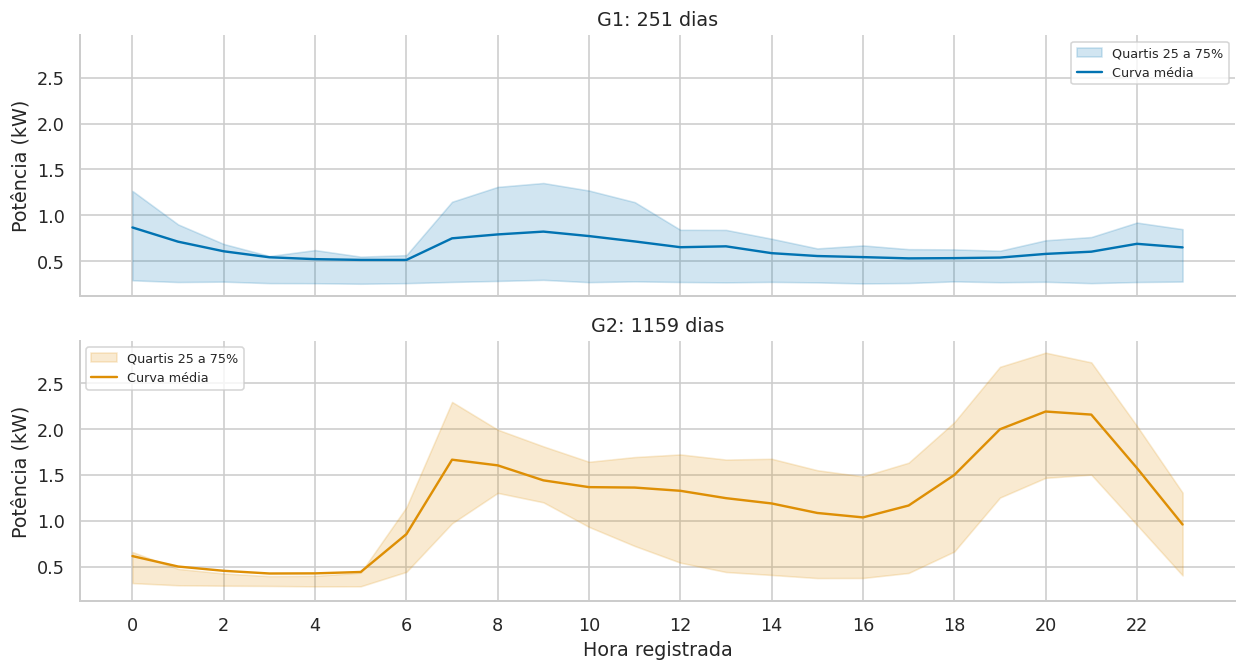

,grupo,dia_proximo_ao_centro,hora_pico_curva_media
0,G1,2010-03-02,0
1,G2,2008-03-10,20


**Análise dos resultados.** **G1** reúne 251 dias (17,80%), com mediana de 13,84 kWh/dia, pico mediano de 2,25 kW e 14,33% da energia entre 18h e 22h. Sua curva média tem máximo às 00h. **G2** reúne 1.159 dias (82,20%), com mediana de 27,48 kWh/dia, pico mediano de 4,11 kW e 26,92% da energia entre 18h e 22h. Sua curva média tem máximo às 20h. Esses contrastes permitem associar cada perfil a intensidade e horários de demanda, sem atribuir automaticamente hábitos ou equipamentos específicos.

In [17]:
diario['rotulo_original'] = rotulos_kmeans
ordem = diario.groupby('rotulo_original').energia_kwh.mean().sort_values().index.tolist()
mapa_grupos = {rotulo: f'G{i+1}' for i, rotulo in enumerate(ordem)}
diario['grupo'] = diario.rotulo_original.map(mapa_grupos)
grupos_ordenados = list(mapa_grupos.values())
cores_grupos = dict(zip(grupos_ordenados, sns.color_palette('colorblind', k_escolhido)))

resumo_grupos = diario.groupby('grupo').agg(
    dias=('energia_kwh', 'size'), energia_media_kwh=('energia_kwh', 'mean'),
    energia_mediana_kwh=('energia_kwh', 'median'), pico_mediano_kw=('pico_15min_kw', 'median'),
    fator_carga_mediano=('fator_carga', 'median'),
    madrugada_mediana=('fracao_madrugada', 'median'), noite_mediana=('fracao_noite', 'median'))
resumo_grupos['dias_%'] = 100*resumo_grupos.dias/len(diario)
resumo_grupos['energia_%'] = 100*diario.groupby('grupo').energia_kwh.sum()/diario.energia_kwh.sum()
display(resumo_grupos)

fig, eixos = plt.subplots(k_escolhido, 1, figsize=(11, 3*k_escolhido), sharex=True, sharey=True, squeeze=False)
representantes = []
curvas_grupos = {}
for i, grupo in enumerate(grupos_ordenados):
    mascara = diario.grupo.eq(grupo)
    subcurvas = curvas.loc[mascara]
    media = subcurvas.mean()
    curvas_grupos[grupo] = media
    ax = eixos[i, 0]
    ax.fill_between(range(24), subcurvas.quantile(.25), subcurvas.quantile(.75),
                    color=cores_grupos[grupo], alpha=.18, label='Quartis 25 a 75%')
    ax.plot(range(24), media, color=cores_grupos[grupo], label='Curva média')
    ax.set(ylabel='Potência (kW)', title=f'{grupo}: {mascara.sum()} dias')
    ax.legend(fontsize=8)
    rotulo = ordem[i]
    indices = np.flatnonzero(mascara.to_numpy())
    melhor = indices[np.argmin(np.linalg.norm(X[indices]-kmeans.cluster_centers_[rotulo], axis=1))]
    representantes.append([grupo, diario.index[melhor].date(), int(media.idxmax())])
eixos[-1,0].set(xlabel='Hora registrada', xticks=range(0,24,2))
plt.tight_layout(); plt.show()
display(pd.DataFrame(representantes, columns=['grupo', 'dia_proximo_ao_centro', 'hora_pico_curva_media']))
textos = []
for grupo in grupos_ordenados:
    r = resumo_grupos.loc[grupo]
    textos.append(f'**{grupo}** reúne {br(r["dias"],0)} dias ({br(r["dias_%"])}%), '
                  f'com mediana de {br(r.energia_mediana_kwh)} kWh/dia, pico mediano '
                  f'de {br(r.pico_mediano_kw)} kW e {br(100*r.noite_mediana)}% '
                  f'da energia entre 18h e 22h. Sua curva média tem máximo às '
                  f'{int(curvas_grupos[grupo].idxmax()):02d}h.')
analise(' '.join(textos) + ' Esses contrastes permitem associar cada perfil a '
        'intensidade e horários de demanda, sem atribuir automaticamente hábitos ou equipamentos específicos.')

**Explicação do algoritmo**

A tabela agrupa os valores originais pela partição aprendida. A participação em energia considera a soma de cada grupo em relação ao total; pode ser alta mesmo quando o grupo contém poucos dias. As frações de janela são medianas de proporções diárias, diferentes de uma razão calculada pela energia total acumulada.

Para cada grupo, as curvas horárias são resumidas por média e quartis. O representante real é selecionado pela menor distância ao centro nos quatro atributos padronizados, entre os próprios membros do grupo. Ele pode não ser o dia mais próximo da curva média horária, pois essa curva não foi a representação utilizada no ajuste principal.

## 18. Relação dos grupos com calendário e qualidade dos dados

Variáveis que ficaram fora do agrupamento podem ajudar a explicar seus resultados. Uma tabela normalizada por linha responde, por exemplo, qual proporção dos dias de determinado mês pertence a cada grupo. A associação com calendário pode revelar sazonalidade ou mudança de regime, sem significar que o algoritmo tenha recebido o mês como entrada.

Também é necessário examinar imputação. Se um grupo apresentar proporção maior de valores estimados, pode estar relacionado ao tratamento de falhas. A comparação é descritiva; diferenças não demonstram, por si mesmas, um artefato. A retenção mensal apresentada anteriormente deve acompanhar a leitura.

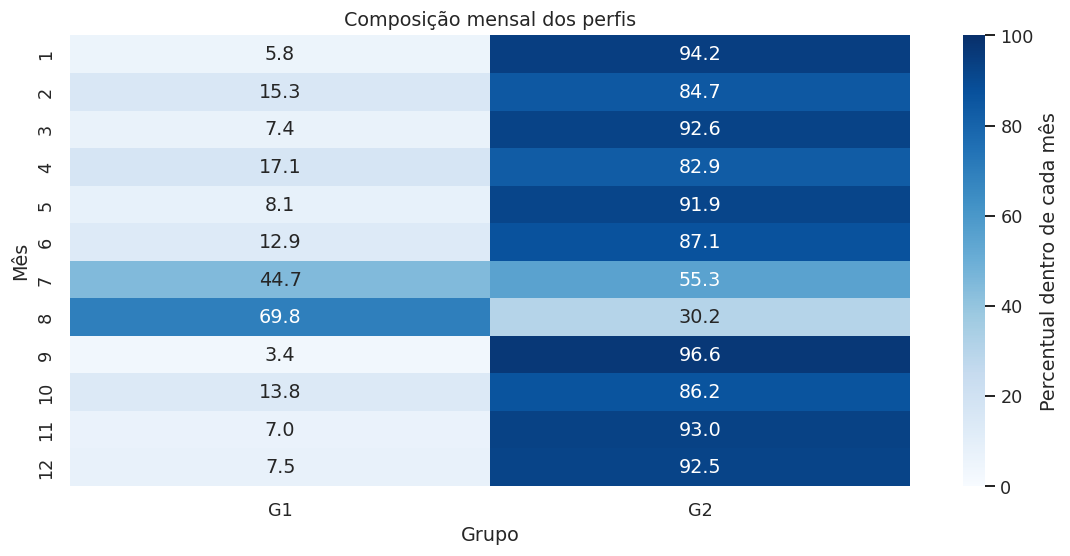

grupo,G1,G2
fim_semana,,
Fim de semana,21.914,78.086
Segunda a sexta,16.190,83.810


,minutos_imputados_medios,dias_com_imputacao
grupo,,
G1,0.008,0.797
G2,0.060,4.314


**Análise dos resultados.** O grupo G1 apresentou proporções entre 3,45% no mês 9 e 69,83% no mês 8. Essa concentração mensal sugere regimes associados à época do ano; ocupação e clima seriam hipóteses a verificar com novas variáveis. As linhas das tabelas de composição somam 100% e usam apenas dias retidos. A auditoria mostra quanto cada grupo dependeu de preenchimento, informação necessária para distinguir padrão de consumo e efeito de qualidade.

In [18]:
composicao_mes = pd.crosstab(diario.mes, diario.grupo, normalize='index').reindex(columns=grupos_ordenados)*100
composicao_semana = pd.crosstab(diario.fim_semana.map({False:'Segunda a sexta', True:'Fim de semana'}),
                               diario.grupo, normalize='index').reindex(columns=grupos_ordenados)*100
auditoria_grupos = diario.groupby('grupo').agg(
    minutos_imputados_medios=('minutos_imputados','mean'),
    dias_com_imputacao=('minutos_imputados', lambda x: 100*x.gt(0).mean()))
fig, ax = plt.subplots(figsize=(10,5))
sns.heatmap(composicao_mes, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=100,
            cbar_kws={'label':'Percentual dentro de cada mês'}, ax=ax)
ax.set(title='Composição mensal dos perfis', xlabel='Grupo', ylabel='Mês')
plt.tight_layout(); plt.show()
display(composicao_semana)
display(auditoria_grupos)
grupo_sazonal = composicao_mes.std().idxmax()
analise(f'O grupo {grupo_sazonal} apresentou proporções entre '
        f'{br(composicao_mes[grupo_sazonal].min())}% no mês '
        f'{int(composicao_mes[grupo_sazonal].idxmin())} e '
        f'{br(composicao_mes[grupo_sazonal].max())}% no mês '
        f'{int(composicao_mes[grupo_sazonal].idxmax())}. Essa concentração mensal '
        'sugere regimes associados à época do ano; ocupação e clima seriam hipóteses '
        'a verificar com novas variáveis. As linhas das tabelas de composição '
        'somam 100% e usam apenas dias retidos. A auditoria mostra quanto cada grupo '
        'dependeu de preenchimento, informação necessária para distinguir padrão de consumo e efeito de qualidade.')

**Explicação do algoritmo**

`crosstab(..., normalize='index')` divide cada contagem pelo total de sua linha. Isso evita que meses com mais dias pareçam mais associados a um grupo apenas por tamanho amostral. A mesma operação é aplicada às categorias de calendário semanal.

A tabela de qualidade calcula o número médio de minutos preenchidos e o percentual de dias com alguma interpolação em cada grupo. O desvio padrão das participações mensais identifica o grupo com maior variação ao longo do calendário. O resultado é um diagnóstico posterior ao ajuste e não uma variável utilizada para construir os centroides.

## 19. Agrupamento hierárquico aglomerativo com método de Ward

O agrupamento hierárquico começa com cada observação em seu próprio grupo e realiza fusões sucessivas. No método de Ward, a cada passo são unidos os grupos cujo encontro produz o menor aumento na soma dos quadrados interna. Para dois grupos A e B, esse aumento é proporcional a $[n_A n_B/(n_A+n_B)]\|\bar{x}_A-\bar{x}_B\|^2$.

O dendrograma registra a sequência das fusões. Ramos que se unem mais acima exigem maior mudança na compactação. O gráfico será truncado para mostrar as últimas fusões, pois desenhar todos os dias tornaria a leitura impraticável. A solução será cortada no mesmo K do K-means para comparar duas estratégias na mesma representação.

Ward utiliza geometria euclidiana e favorece grupos compactos. Seu custo de memória cresce aproximadamente com o quadrado do número de observações, razão para aplicá-lo aos dias agregados e não aos mais de dois milhões de minutos.

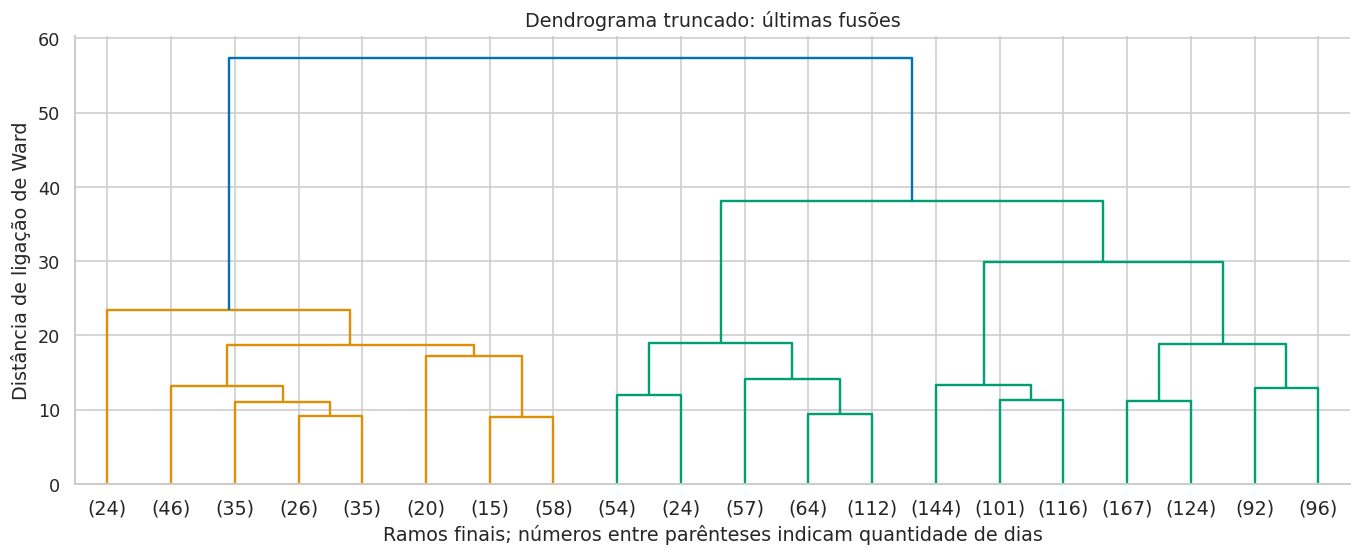

Ward,0,1
grupo,,
G1,24,227
G2,1127,32


**Análise dos resultados.** Ward produziu 2 grupos, com silhueta 0,393 e ARI de 0,817 em relação ao K-means. A tabela indica quais perfis foram preservados ou divididos. Concordância entre algoritmos reforça a consistência geométrica observada, mas não funciona como validação por rótulos verdadeiros.

In [19]:
hierarquico = AgglomerativeClustering(n_clusters=k_escolhido, linkage='ward')
rotulos_ward = hierarquico.fit_predict(X)
ligacoes = linkage(X, method='ward')
fig, ax = plt.subplots(figsize=(12,5))
dendrogram(ligacoes, truncate_mode='lastp', p=20, show_leaf_counts=True, ax=ax)
ax.set(xlabel='Ramos finais; números entre parênteses indicam quantidade de dias',
       ylabel='Distância de ligação de Ward', title='Dendrograma truncado: últimas fusões')
plt.tight_layout(); plt.show()
ari_ward = adjusted_rand_score(rotulos_kmeans, rotulos_ward)
sil_ward = silhouette_score(X, rotulos_ward)
display(pd.crosstab(diario.grupo, pd.Series(rotulos_ward, index=diario.index, name='Ward')))
analise(f'Ward produziu {k_escolhido} grupos, com silhueta {br(sil_ward,3)} e '
        f'ARI de {br(ari_ward,3)} em relação ao K-means. A tabela indica quais perfis '
        'foram preservados ou divididos. Concordância entre algoritmos reforça a '
        'consistência geométrica observada, mas não funciona como validação por rótulos verdadeiros.')

**Explicação do algoritmo**

`AgglomerativeClustering` fornece os rótulos da partição no K escolhido. `linkage` calcula a árvore de fusões necessária ao dendrograma. As duas implementações aplicam Ward à mesma matriz; diferenças em empates de distância são possíveis.

O truncamento mantém somente os últimos vinte ramos visíveis, sem reduzir os dados usados na construção da árvore. A tabela cruzada mostra a correspondência entre grupos. ARI e silhueta respondem a perguntas diferentes: o primeiro mede concordância com outra partição, enquanto a segunda descreve coesão e separação nos atributos.

## 20. DBSCAN: densidade, vizinhança e dias pouco recorrentes

O DBSCAN forma grupos a partir de regiões densas. Um ponto é central quando sua vizinhança de raio `eps` contém pelo menos `min_samples` observações, contando o próprio ponto. Regiões centrais conectadas são expandidas; pontos de borda podem pertencer a um grupo sem satisfazer o critério central. Observações não alcançadas recebem o rótulo −1, denominado ruído.

Ruído significa baixa densidade na representação e nos parâmetros escolhidos. Pode corresponder a um dia raro, a uma transição ou a um problema de medição. Não constitui diagnóstico automático de defeito, fraude ou risco elétrico.

O raio será explorado por quantis da distância ao décimo vizinho, contando o próprio dia entre os dez. Essa é uma estratégia explícita de sensibilidade. A configuração de referência utilizará o percentil 80 dessas distâncias e `min_samples=10`. A tabela completa será mantida para mostrar como as escolhas afetam cobertura e quantidade de grupos. Não será forçada uma separação em vários grupos.

,quantil_eps,eps,grupos,cobertura_%,silhueta_sem_ruido
0,0.50,0.502,4,67.305,0.494
1,0.65,0.606,4,78.369,0.438
2,0.80,0.776,3,89.574,0.476
3,0.90,1.001,2,95.674,0.531
4,0.95,1.239,2,98.298,0.512


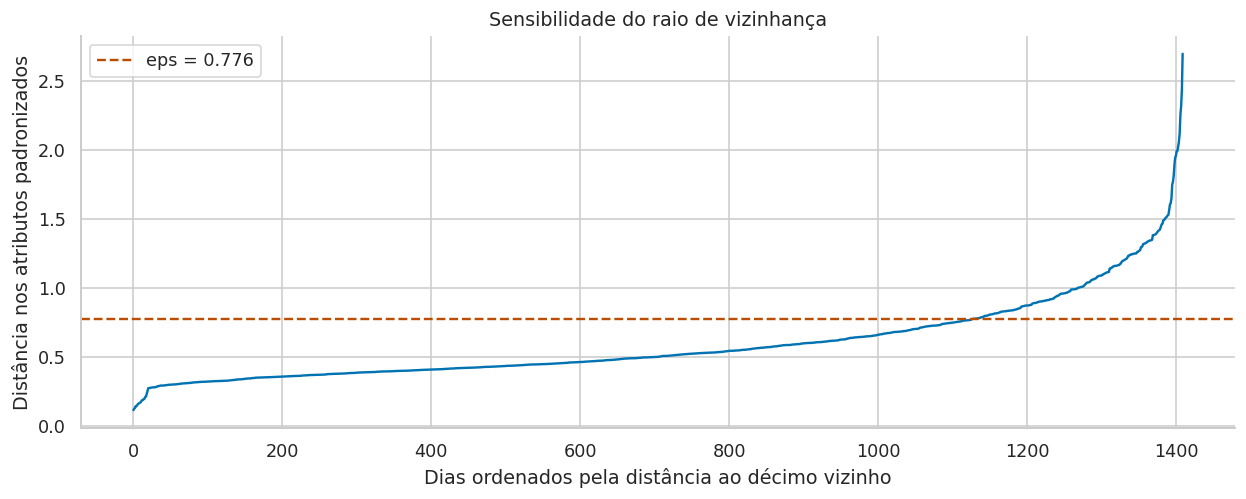

,energia_kwh,pico_15min_kw,fator_carga,minutos_imputados
ruido_dbscan,,,,
Regiões agrupadas,26.075,3.882,0.279,0.0
Ruído,24.253,3.641,0.306,0.0


**Análise dos resultados.** Com eps=0,776, foram encontrados 3 grupos e 147 dias de ruído (10,43%). A silhueta disponível considera somente os dias agrupados. A variação da tabela evidencia a dependência dos parâmetros. Os dias de ruído constituem uma fila de inspeção, sem diagnóstico físico automático.

In [20]:
MIN_AMOSTRAS = 10
vizinhos = NearestNeighbors(n_neighbors=MIN_AMOSTRAS).fit(X)
distancias, _ = vizinhos.kneighbors(X)
distancia_k = np.sort(distancias[:, -1])
quantis_eps = [.50, .65, .80, .90, .95]
sensibilidade_db = []
rotulos_db_por_q = {}
for quantil in quantis_eps:
    eps = max(float(np.quantile(distancia_k, quantil)), np.finfo(float).eps)
    rotulos = DBSCAN(eps=eps, min_samples=MIN_AMOSTRAS).fit_predict(X)
    rotulos_db_por_q[quantil] = rotulos
    dentro = rotulos != -1
    n_grupos = len(set(rotulos[dentro]))
    sil = (silhouette_score(X[dentro], rotulos[dentro])
           if 2 <= n_grupos < dentro.sum() else np.nan)
    sensibilidade_db.append([quantil, eps, n_grupos, 100*dentro.mean(), sil])
tabela_db = pd.DataFrame(sensibilidade_db, columns=['quantil_eps','eps','grupos','cobertura_%','silhueta_sem_ruido'])
rotulos_db = rotulos_db_por_q[.80]
eps_escolhido = float(tabela_db.loc[tabela_db.quantil_eps.eq(.80), 'eps'].iloc[0])
diario['ruido_dbscan'] = rotulos_db == -1
display(tabela_db)
plt.plot(distancia_k)
plt.axhline(eps_escolhido, color='#bb4d00', ls='--', label=f'eps = {eps_escolhido:.3f}')
plt.xlabel('Dias ordenados pela distância ao décimo vizinho')
plt.ylabel('Distância nos atributos padronizados')
plt.title('Sensibilidade do raio de vizinhança'); plt.legend(); plt.tight_layout(); plt.show()
resumo_ruido = diario.groupby('ruido_dbscan')[['energia_kwh','pico_15min_kw','fator_carga','minutos_imputados']].median()
display(resumo_ruido.rename(index={False:'Regiões agrupadas', True:'Ruído'}))
n_grupos_db = len(set(rotulos_db)) - int(-1 in rotulos_db)
analise(f'Com eps={br(eps_escolhido,3)}, foram encontrados {n_grupos_db} grupos e '
        f'{br(diario.ruido_dbscan.sum(),0)} dias de ruído ({br(100*diario.ruido_dbscan.mean())}%). '
        + ('A silhueta entre grupos não se aplica a esta configuração, pois não há pelo menos dois grupos não ruidosos. '
           if n_grupos_db < 2 else 'A silhueta disponível considera somente os dias agrupados. ')
        + 'A variação da tabela evidencia a dependência dos parâmetros. Os dias de ruído '
          'constituem uma fila de inspeção, sem diagnóstico físico automático.')

**Explicação do algoritmo**

`kneighbors(X)` consulta os próprios dados, de modo que a distância zero ao próprio dia participa da contagem, consistente com `min_samples` do DBSCAN. O último valor de cada linha corresponde ao limite da vizinhança de dez observações. Seus quantis geram uma faixa reproduzível de raios candidatos.

O laço calcula grupos, cobertura e silhueta apenas quando esta é matematicamente definida. O rótulo −1 é removido do cálculo da silhueta porque não representa um grupo coeso. A configuração do percentil 80 é uma referência didática, não um parâmetro validado operacionalmente. A comparação das medianas ajuda a caracterizar os dias raros e a verificar sua relação com imputação.

## 21. Comparação dos métodos na mesma representação

Comparar algoritmos exige esclarecer o que cada métrica avalia. K-means e Ward atribuem todos os dias a grupos. DBSCAN pode recusar parte das observações, portanto uma silhueta calculada apenas nos dias aceitos não é diretamente equivalente a uma silhueta calculada no conjunto inteiro. Uma comparação completa precisa mostrar a cobertura.

Todos os métodos serão desenhados na mesma projeção PCA, mantendo a mesma escala dos eixos. As métricas continuam calculadas nos quatro atributos originais padronizados. Ausência de rótulos externos impede calcular acurácia, precisão ou matriz de confusão com significado supervisionado.

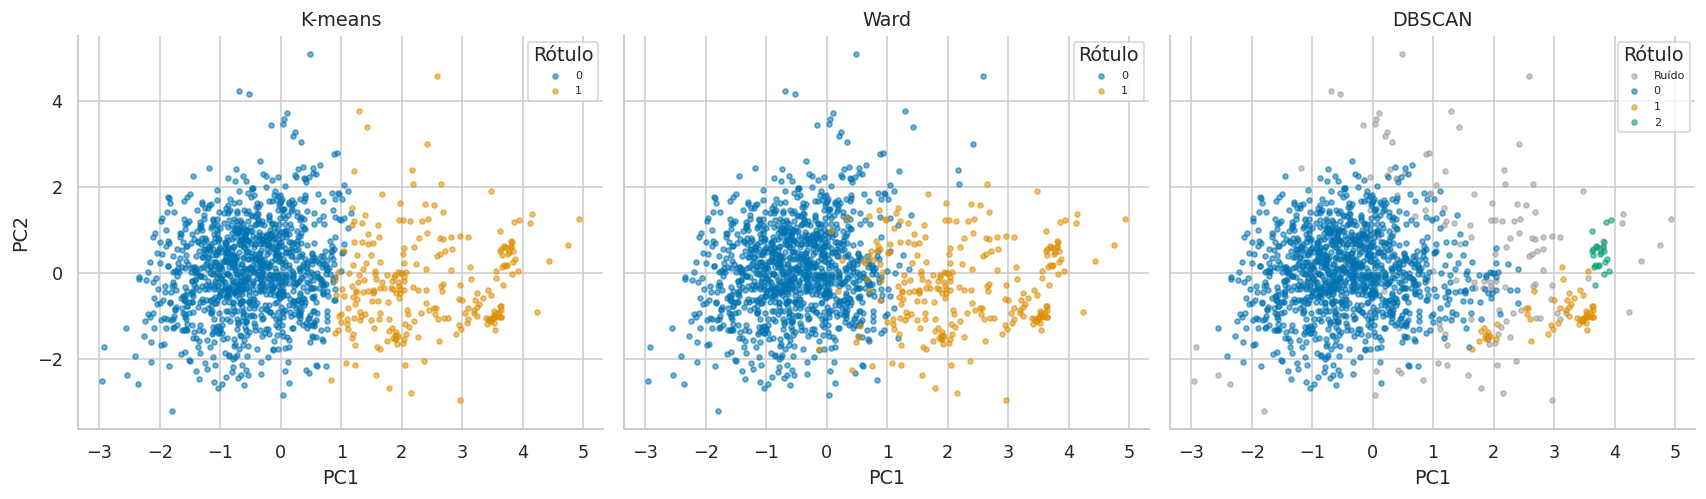

,metodo,grupos,cobertura_%,silhueta_dias_agrupados,davies_bouldin
0,K-means,2,100.000,0.413,1.143
1,Ward,2,100.000,0.393,1.196
2,DBSCAN,3,89.574,0.476,0.554


**Análise dos resultados.** K-means e Ward classificaram todos os 1.410 dias. O DBSCAN cobriu 89,57% deles. As cores e os números são identificadores próprios de cada método. A escolha operacional depende de desejar segmentar todos os dias ou destacar ocorrências de baixa recorrência; a maior silhueta isolada não resolve essa decisão.

In [21]:
linhas_comparacao = []
particoes = {'K-means': rotulos_kmeans, 'Ward': rotulos_ward, 'DBSCAN': rotulos_db}
fig, eixos = plt.subplots(1,3, figsize=(15,4.5), sharex=True, sharey=True)
for ax, (nome, rotulos) in zip(eixos, particoes.items()):
    validos = rotulos != -1
    ng = len(set(rotulos[validos]))
    sil = silhouette_score(X[validos], rotulos[validos]) if 2 <= ng < validos.sum() else np.nan
    dbi = davies_bouldin_score(X[validos], rotulos[validos]) if 2 <= ng < validos.sum() else np.nan
    linhas_comparacao.append([nome, ng, 100*validos.mean(), sil, dbi])
    for rotulo in sorted(set(rotulos)):
        m = rotulos == rotulo
        cor = '#9b9b9b' if rotulo == -1 else sns.color_palette('colorblind')[int(rotulo)%10]
        ax.scatter(projecao[m,0], projecao[m,1], s=10, alpha=.55, color=cor,
                   label='Ruído' if rotulo == -1 else str(rotulo))
    ax.set(title=nome, xlabel='PC1')
    ax.legend(fontsize=7, title='Rótulo')
eixos[0].set_ylabel('PC2'); plt.tight_layout(); plt.show()
comparacao = pd.DataFrame(linhas_comparacao,
    columns=['metodo','grupos','cobertura_%','silhueta_dias_agrupados','davies_bouldin'])
display(comparacao)
analise(f'K-means e Ward classificaram todos os {br(len(X),0)} dias. '
        f'O DBSCAN cobriu {br(100*np.mean(rotulos_db!=-1))}% deles. '
        'As cores e os números são identificadores próprios de cada método. '
        'A escolha operacional depende de desejar segmentar todos os dias ou destacar '
        'ocorrências de baixa recorrência; a maior silhueta isolada não resolve essa decisão.')

**Explicação do algoritmo**

O dicionário mantém nome e rótulos de cada método. Para cada partição, o código identifica observações agrupadas, verifica o número de grupos e calcula métricas somente quando definidas. `NaN` representa ausência de uma métrica válida, e não desempenho igual a zero.

Os três gráficos compartilham os eixos para tornar comparáveis as posições. O ruído recebe cinza, mas os demais rótulos não são alinhados semanticamente entre algoritmos. A interpretação conjunta usa geometria, cobertura, concordância e significado físico, sem criar um ranking universal.

## 22. Outra pergunta: agrupamento pelo formato da curva de carga

Dois dias podem ter o mesmo formato horário e níveis de energia muito diferentes. Se a pergunta for quando o consumo se concentra, pode-se dividir cada curva pela própria potência média: $r_{d,h}=P_{d,h}/\bar{P}_d$. Cada dia passa a ter média 1. O valor 2, por exemplo, indica potência horária igual ao dobro da média daquele dia.

Essa normalização por linha remove o nível global, ao contrário da padronização por coluna usada anteriormente. As 24 horas já ficam na mesma escala relativa; nenhuma nova padronização por hora será aplicada, preservando pesos iguais para desvios relativos em cada posição horária. Dias de consumo muito baixo podem ter flutuações relativas expressivas.

Será mantido o mesmo K apenas para isolar parte do efeito da representação. O K ótimo por outro critério poderia mudar e precisaria de nova avaliação em uma aplicação dedicada ao formato. O ARI medirá quanto essa pergunta produz uma partição diferente.

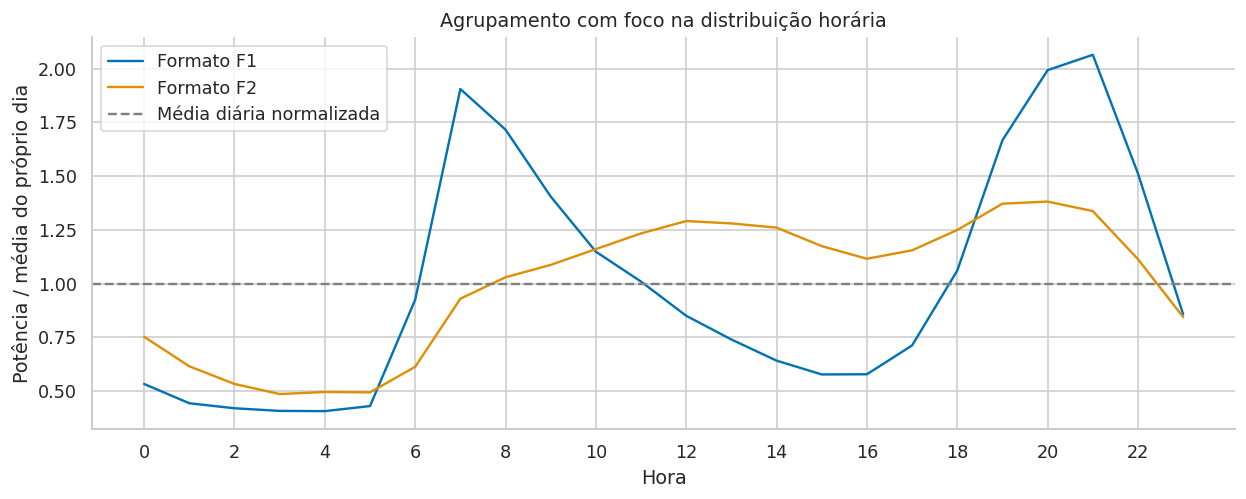

Formato,1,2
grupo,,
G1,66,185
G2,648,511


**Análise dos resultados.** A partição por formato apresentou ARI de 0,032 em relação à segmentação principal e silhueta de 0,130 na nova representação. Esse valor de silhueta é baixo e indica sobreposição relevante: os perfis devem ser lidos como resumos de uma variação contínua. Os grupos agora descrevem horários relativos de concentração do consumo. Essa mudança evidencia que a inteligência extraída depende da pergunta e dos atributos escolhidos, não apenas do nome do algoritmo.

In [22]:
curvas_relativas = curvas.div(curvas.mean(axis=1), axis=0)
assert np.allclose(curvas_relativas.mean(axis=1), 1)
modelo_formato = KMeans(n_clusters=k_escolhido, n_init=20, random_state=SEMENTE)
rotulos_formato = modelo_formato.fit_predict(curvas_relativas)
ari_formato = adjusted_rand_score(rotulos_kmeans, rotulos_formato)
sil_formato = silhouette_score(curvas_relativas, rotulos_formato)

fig, ax = plt.subplots(figsize=(11,4.5))
for grupo in range(k_escolhido):
    curva = curvas_relativas.loc[rotulos_formato == grupo].mean()
    ax.plot(range(24), curva, label=f'Formato F{grupo+1}')
ax.axhline(1, color='gray', ls='--', label='Média diária normalizada')
ax.set(xlabel='Hora', ylabel='Potência / média do próprio dia', xticks=range(0,24,2),
       title='Agrupamento com foco na distribuição horária')
ax.legend(); plt.tight_layout(); plt.show()
display(pd.crosstab(diario.grupo, pd.Series(rotulos_formato+1, index=diario.index, name='Formato')))
analise(f'A partição por formato apresentou ARI de {br(ari_formato,3)} em relação '
        f'à segmentação principal e silhueta de {br(sil_formato,3)} na nova representação. '
        + ('Esse valor de silhueta é baixo e indica sobreposição relevante: os perfis '
           'devem ser lidos como resumos de uma variação contínua. ' if sil_formato < .25 else '')
        +
        'Os grupos agora descrevem horários relativos de concentração do consumo. '
        'Essa mudança evidencia que a inteligência extraída depende da pergunta e '
        'dos atributos escolhidos, não apenas do nome do algoritmo.')

**Explicação do algoritmo**

`div(..., axis=0)` divide cada linha por sua média. A asserção verifica a propriedade de média unitária. O K-means passa a receber 24 atributos relativos, um por hora, em vez dos quatro indicadores da segmentação principal.

As curvas desenhadas são médias relativas e não devem ser lidas em kW. A tabela cruzada revela como os dias foram redistribuídos. A silhueta é calculada no novo espaço e não constitui uma comparação estrita de qualidade com a silhueta da representação anterior, pois a noção de distância foi modificada.

## 23. Dos perfis à gestão da demanda: cenário explícito de deslocamento

Um insight operacional relaciona uma evidência a uma decisão verificável. A concentração de consumo em uma janela pode motivar o estudo de cargas deslocáveis. A base não informa disponibilidade de controle, conforto ou flexibilidade de cada equipamento, portanto será elaborado um **cenário hipotético**, com hipóteses explícitas.

O cenário transfere 20% da energia entre 18h e 22h para 00h a 06h do mesmo dia contábil, distribuindo-a igualmente nas seis horas receptoras. Essa realocação representa uma comparação de programação horária; antecipar energia exige que o serviço permita tal programação. A conservação impõe $\sum_h E^{\text{depois}}_{d,h}=\sum_h E^{\text{antes}}_{d,h}$.

Reduzir energia na janela não garante reduzir o pico diário, pois o maior valor pode estar em outro horário ou surgir na janela receptora. Por isso, o algoritmo recalculará o máximo de cada dia. O pico analisado aqui é **horário**, compatível com as curvas utilizadas, e difere do pico de 15 minutos das etapas anteriores. Não se estima economia financeira, pois não há tarifa nem custos de controle definidos.

,energia_transferida_media_kwh,pico_antes_medio_kw,pico_depois_medio_kw,reducao_mediana_pct,dias_com_reducao_pct,dias_com_aumento_pct
grupo,,,,,,
G1,0.451,1.730,1.731,0.000,7.968,31.076
G2,1.568,3.118,2.840,2.619,53.149,0.518


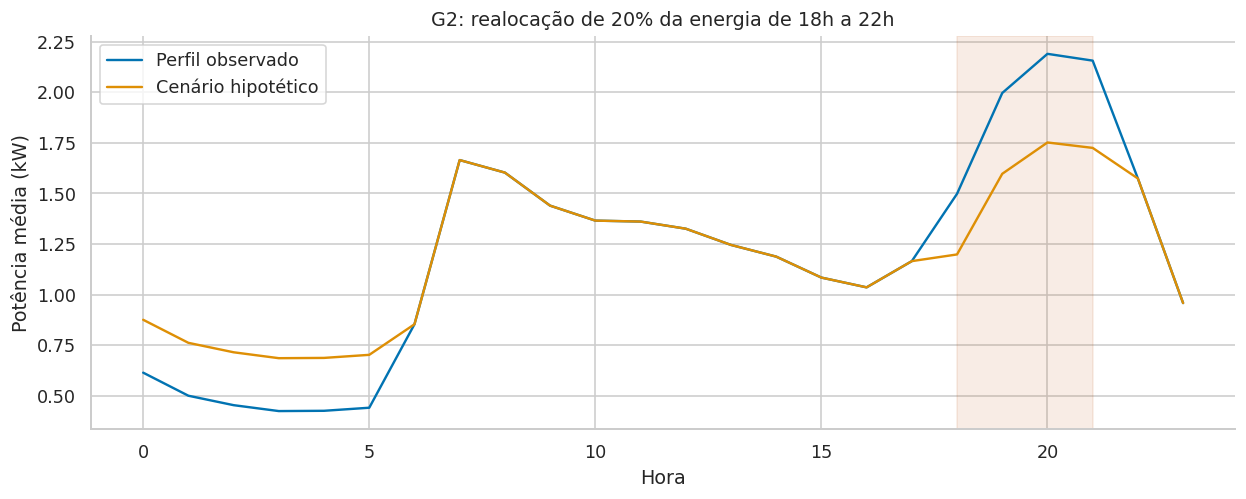

**Análise dos resultados.** O cenário deslocou em média 1,37 kWh por dia. O pico horário caiu em 45,11% dos dias e aumentou em 5,96%. A energia total permaneceu constante. O resultado quantifica uma hipótese de programação; sua implementação exigiria identificar cargas realmente flexíveis e verificar restrições de serviço, instalação e horário.

In [23]:
FRACAO_DESLOCADA = .20
horas_receptoras = list(range(0,6))
depois = curvas.copy()
energia_transferida = FRACAO_DESLOCADA * curvas.loc[:, HORAS_NOITE].sum(axis=1)
depois.loc[:, HORAS_NOITE] = curvas.loc[:, HORAS_NOITE] * (1-FRACAO_DESLOCADA)
depois.loc[:, horas_receptoras] = curvas.loc[:, horas_receptoras].add(
    energia_transferida/len(horas_receptoras), axis=0)
assert np.allclose(depois.sum(axis=1), curvas.sum(axis=1))
assert depois.ge(0).all().all()

cenario = pd.DataFrame({'grupo': diario.grupo,
    'energia_transferida_kwh': energia_transferida,
    'pico_horario_antes_kw': curvas.max(axis=1),
    'pico_horario_depois_kw': depois.max(axis=1)})
cenario['reducao_pico_%'] = 100*(1-cenario.pico_horario_depois_kw/cenario.pico_horario_antes_kw)
resumo_cenario = cenario.groupby('grupo').agg(
    energia_transferida_media_kwh=('energia_transferida_kwh','mean'),
    pico_antes_medio_kw=('pico_horario_antes_kw','mean'),
    pico_depois_medio_kw=('pico_horario_depois_kw','mean'),
    reducao_mediana_pct=('reducao_pico_%','median'),
    dias_com_reducao_pct=('reducao_pico_%',lambda x: 100*x.gt(1e-8).mean()),
    dias_com_aumento_pct=('reducao_pico_%',lambda x: 100*x.lt(-1e-8).mean()))
display(resumo_cenario)
grupo_exemplo = resumo_grupos.noite_mediana.idxmax()
m = diario.grupo.eq(grupo_exemplo)
plt.plot(range(24), curvas.loc[m].mean(), label='Perfil observado')
plt.plot(range(24), depois.loc[m].mean(), label='Cenário hipotético')
plt.axvspan(18,21, color='#bb4d00', alpha=.1)
plt.xlabel('Hora'); plt.ylabel('Potência média (kW)')
plt.title(f'{grupo_exemplo}: realocação de 20% da energia de 18h a 22h')
plt.legend(); plt.tight_layout(); plt.show()
analise(f'O cenário deslocou em média {br(energia_transferida.mean())} kWh por dia. '
        f'O pico horário caiu em {br(100*cenario["reducao_pico_%"].gt(1e-8).mean())}% dos dias '
        f'e aumentou em {br(100*cenario["reducao_pico_%"].lt(-1e-8).mean())}%. '
        'A energia total permaneceu constante. O resultado quantifica uma hipótese de '
        'programação; sua implementação exigiria identificar cargas realmente flexíveis '
        'e verificar restrições de serviço, instalação e horário.')

**Explicação do algoritmo**

A energia da janela é obtida somando potências médias de intervalos de uma hora. O algoritmo reduz cada hora doadora na fração definida e adiciona a energia retirada uniformemente às horas receptoras. Como a duração é uma hora, a quantidade em kWh por intervalo corresponde numericamente ao acréscimo em kW médio.

As asserções verificam conservação da energia e ausência de potências negativas. O máximo é recalculado dia a dia antes da agregação por grupo. Isso evita confundir o pico da curva média com a média dos picos diários. Valores negativos na redução percentual representam aumento do pico e são preservados. O grupo mostrado no gráfico é escolhido pela maior participação noturna mediana observada.

## 24. Síntese das descobertas: evidência, interpretação e decisão

Extrair inteligência consiste em transformar resultados verificáveis em hipóteses e decisões delimitadas. Uma tabela de grupos, isoladamente, não oferece uma ação. A conexão exige identificar o que foi medido, o que o resultado sugere e qual informação adicional seria necessária para agir.

As descobertas abaixo são calculadas a partir desta execução. Elas combinam qualidade, carga, segmentação e o cenário de deslocamento. Nenhuma linha presume causalidade, custo monetário ou capacidade de controle que não tenha sido medida. Para transportar o fluxo a uma rede inteligente, seria necessário acrescentar identificador do medidor, sincronização temporal, topologia quando pertinente e validação em períodos posteriores.

In [24]:
grupo_energia = resumo_grupos['energia_%'].idxmax()
grupo_noite = resumo_grupos.noite_mediana.idxmax()
descobertas = pd.DataFrame([
    ['Qualidade', f'{len(diario)} de {len(qualidade)} dias retidos',
     'Falhas longas alteram a amostra disponível',
     'Acompanhar cobertura antes de comparar consumo entre períodos'],
    ['Horário', f'Pico da curva média às {hora_max:02d}h: {br(curva_media.max())} kW',
     'Há concentração horária da solicitação média',
     'Examinar cargas presentes nessa janela e variabilidade entre dias'],
    ['Participação energética', f'{grupo_energia}: {br(resumo_grupos.loc[grupo_energia,"energia_%"])}% da energia',
     'Esse perfil concentra a maior parcela do consumo analisado',
     'Priorizar investigação dos equipamentos e condições associados'],
    ['Concentração noturna', f'{grupo_noite}: mediana de {br(100*resumo_grupos.loc[grupo_noite,"noite_mediana"])}% entre 18h e 22h',
     'Esse perfil apresenta a maior participação noturna mediana',
     'Verificar disponibilidade real de cargas deslocáveis'],
    ['Recorrência', f'{int(diario.ruido_dbscan.sum())} dias com rótulo de ruído no DBSCAN',
     'Há dias pouco recorrentes na configuração adotada',
     'Inspecionar curvas e qualidade antes de atribuir uma causa'],
    ['Cenário', f'{br(100*cenario["reducao_pico_%"].gt(1e-8).mean())}% dos dias com redução do pico horário',
     'Deslocar energia não reduz necessariamente o maior valor diário',
     'Validar flexibilidade e simular restrições por equipamento']
], columns=['dimensao', 'evidencia_calculada', 'interpretacao', 'decisao_a_investigar'])
display(descobertas)
analise('O fluxo converteu medições em indicadores e perfis interpretáveis. '
        'Os resultados sustentam prioridades de investigação e cenários de demanda. '
        'A aplicação a uma população de consumidores exigiria novos medidores e '
        'validação externa; a aplicação futura a esta residência exigiria avaliar '
        'mudanças de regime e manter os critérios de qualidade.')

,dimensao,evidencia_calculada,interpretacao,decisao_a_investigar
0,Qualidade,1410 de 1442 dias retidos,Falhas longas alteram a amostra disponível,Acompanhar cobertura antes de comparar consumo entre períodos
1,Horário,"Pico da curva média às 20h: 1,90 kW",Há concentração horária da solicitação média,Examinar cargas presentes nessa janela e variabilidade entre dias
2,Participação energética,"G2: 89,63% da energia",Esse perfil concentra a maior parcela do consumo analisado,Priorizar investigação dos equipamentos e condições associados
3,Concentração noturna,"G2: mediana de 26,92% entre 18h e 22h",Esse perfil apresenta a maior participação noturna mediana,Verificar disponibilidade real de cargas deslocáveis
4,Recorrência,147 dias com rótulo de ruído no DBSCAN,Há dias pouco recorrentes na configuração adotada,Inspecionar curvas e qualidade antes de atribuir uma causa
5,Cenário,"45,11% dos dias com redução do pico horário",Deslocar energia não reduz necessariamente o maior valor diário,Validar flexibilidade e simular restrições por equipamento


**Análise dos resultados.** O fluxo converteu medições em indicadores e perfis interpretáveis. Os resultados sustentam prioridades de investigação e cenários de demanda. A aplicação a uma população de consumidores exigiria novos medidores e validação externa; a aplicação futura a esta residência exigiria avaliar mudanças de regime e manter os critérios de qualidade.

**Explicação do algoritmo**

Os grupos de maior contribuição energética e maior fração noturna são selecionados diretamente da tabela de indicadores. Cada linha da síntese utiliza uma quantidade calculada e explicita a interpretação que ela permite. A decisão é formulada como uma investigação delimitada, pois a base não fornece todas as variáveis necessárias a uma intervenção.

Essa estrutura separa resultado, interpretação e ação. A evidência pode ser conferida em uma etapa anterior; a interpretação esclarece seu significado; a decisão indica como utilizar a informação em um processo de engenharia.

## 25. Exportação do conjunto analítico e dos modelos

O resultado de um fluxo de dados deve poder ser reutilizado e auditado. Serão exportados a tabela diária com grupos, curvas horárias, auditorias de qualidade, indicadores de avaliação e a síntese das descobertas. Os modelos serão acompanhados do padronizador, da ordem dos atributos e dos critérios de tratamento.

O arquivo `joblib` representa objetos Python e deve ser carregado apenas quando proveniente de uma fonte confiável. As versões das bibliotecas precisam ser compatíveis para reutilização. O modelo principal exige que novos dias passem pela mesma agregação, transformação logarítmica e padronização. Os números dos grupos não são significados universais; o mapa para G1, G2 e demais rótulos precisa acompanhar o modelo.

In [25]:
PASTA_SAIDA = Path('resultados_energia')
PASTA_SAIDA.mkdir(exist_ok=True)
diario.to_csv(PASTA_SAIDA/'dias_analisados.csv', encoding='utf-8-sig', index_label='data')
curvas.to_csv(PASTA_SAIDA/'curvas_horarias_kw.csv', encoding='utf-8-sig', index_label='data')
qualidade.to_csv(PASTA_SAIDA/'qualidade_por_dia.csv', encoding='utf-8-sig', index_label='data')
resumo_grupos.to_csv(PASTA_SAIDA/'resumo_grupos.csv', encoding='utf-8-sig')
tabela_k.to_csv(PASTA_SAIDA/'avaliacao_k.csv', encoding='utf-8-sig', index=False)
tabela_db.to_csv(PASTA_SAIDA/'sensibilidade_dbscan.csv', encoding='utf-8-sig', index=False)
comparacao.to_csv(PASTA_SAIDA/'comparacao_metodos.csv', encoding='utf-8-sig', index=False)
descobertas.to_csv(PASTA_SAIDA/'descobertas.csv', encoding='utf-8-sig', index=False)
resumo_cenario.to_csv(PASTA_SAIDA/'cenario_deslocamento.csv', encoding='utf-8-sig')
metadados = {'fonte': URL_DADOS, 'doi': '10.24432/C58K54', 'sha256_zip': sha256,
    'versoes': versoes, 'semente': SEMENTE, 'max_lacuna_min': MAX_LACUNA_MIN,
    'cobertura_original_min': COBERTURA_ORIGINAL_MIN, 'dias_retidos': len(diario),
    'atributos': list(atributos.columns), 'transformacao_energia': 'log1p',
    'k': k_escolhido, 'mapa_grupos': {int(k):v for k,v in mapa_grupos.items()},
    'dbscan_eps': eps_escolhido, 'dbscan_min_samples': MIN_AMOSTRAS,
    'cenario_fracao_deslocada': FRACAO_DESLOCADA, 'horas_doadoras': HORAS_NOITE,
    'horas_receptoras': horas_receptoras}
(PASTA_SAIDA/'metadados.json').write_text(json.dumps(metadados, ensure_ascii=False, indent=2), encoding='utf-8')
joblib.dump({'padronizador': padronizador, 'kmeans': kmeans,
             'atributos': list(atributos.columns), 'mapa_grupos': mapa_grupos},
            PASTA_SAIDA/'modelo_perfis.joblib')
arquivo_resultados = shutil.make_archive('resultados_energia', 'zip', PASTA_SAIDA)
print('Arquivo gerado:', arquivo_resultados)
print('Conteúdo:', ', '.join(p.name for p in sorted(PASTA_SAIDA.iterdir())))
analise('As tabelas e o modelo foram exportados junto com as decisões de tratamento e '
        'a identificação do arquivo original. No Colab, o ZIP pode ser baixado pelo painel '
        'de arquivos. Essa entrega permite reutilizar os resultados sem perder a rastreabilidade da análise.')

Arquivo gerado: /workspace/scratch/037db274d670/resultados_energia.zip
Conteúdo: avaliacao_k.csv, cenario_deslocamento.csv, comparacao_metodos.csv, curvas_horarias_kw.csv, descobertas.csv, dias_analisados.csv, metadados.json, modelo_perfis.joblib, qualidade_por_dia.csv, resumo_grupos.csv, sensibilidade_dbscan.csv


**Análise dos resultados.** As tabelas e o modelo foram exportados junto com as decisões de tratamento e a identificação do arquivo original. No Colab, o ZIP pode ser baixado pelo painel de arquivos. Essa entrega permite reutilizar os resultados sem perder a rastreabilidade da análise.

**Explicação do algoritmo**

Os CSVs mantêm datas e nomes de variáveis para facilitar a abertura em outras ferramentas. O JSON registra configurações, fonte e versões. O objeto `joblib` reúne o modelo e a transformação que o antecede, evitando a aplicação dos centroides diretamente a valores em unidades originais.

`make_archive` compacta somente a pasta de resultados, sem incluir novamente o conjunto bruto. O download pode ser feito pelo painel de arquivos do Colab, permitindo selecionar o momento em que se deseja salvar os resultados localmente.

## Referências e documentação técnica

HEBRAIL, Georges; BERARD, Alice. **Individual Household Electric Power Consumption**. UCI Machine Learning Repository, 2006. DOI: [10.24432/C58K54](https://doi.org/10.24432/C58K54). [Descrição, variáveis e licença](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption). Acesso em: 1 set. 2026.

PANDAS DEVELOPMENT TEAM. **pandas.DataFrame.interpolate**. [Documentação da interpolação](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.interpolate.html). Acesso em: 1 set. 2026.

SCIKIT-LEARN DEVELOPERS. **Clustering**. [Fundamentos e avaliação de agrupamentos](https://scikit-learn.org/stable/modules/clustering.html). Acesso em: 1 set. 2026.

SCIKIT-LEARN DEVELOPERS. **KMeans**. [Parâmetros e implementação](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html). Acesso em: 1 set. 2026.

SCIKIT-LEARN DEVELOPERS. **StandardScaler**. [Padronização de atributos](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html). Acesso em: 1 set. 2026.

SCIKIT-LEARN DEVELOPERS. **silhouette_score**. [Definição e condições de cálculo](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html). Acesso em: 1 set. 2026.

SCIKIT-LEARN DEVELOPERS. **DBSCAN**. [Agrupamento por densidade](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html). Acesso em: 1 set. 2026.

SCIPY DEVELOPERS. **scipy.cluster.hierarchy.linkage**. [Métodos de ligação e Ward](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html). Acesso em: 1 set. 2026.

SCIKIT-LEARN DEVELOPERS. **PCA**. [Componentes principais](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html). Acesso em: 1 set. 2026.

KÜNSCH, Hans R. **The Jackknife and the Bootstrap for General Stationary Observations**. The Annals of Statistics, v. 17, n. 3, p. 1217 a 1241, 1989. DOI: [10.1214/aos/1176347265](https://doi.org/10.1214/aos/1176347265). Fundamentação da reamostragem em blocos para observações dependentes.